# Huấn luyện và đánh giá LSTM

**CO5087 – Cách tiếp cận hiện đại trong xử lý ngôn ngữ tự nhiên**

Notebook nhận dataset sạch từ `Dataset_VietNamNet.ipynb`, tiền xử lý tiếng Việt,
mã hóa Head–Tail, huấn luyện BiLSTM và xuất kết quả phục vụ báo cáo cùng suy luận.


## Môi trường thực thi

Chọn kernel **Python 3.14** trên máy có GPU NVIDIA và bấm **Run All**.
Notebook đọc dataset sạch trong `dataset/` và lưu đầu ra ngay trong thư mục dự án.
Phần đầu kiểm tra các thư viện; PyTorch CUDA và GPU được kiểm tra trước tiền xử lý.

- Chia phân tầng **70% train / 15% validation / 15% test**, seed 42, sau khi loại văn bản trùng.
- Validation chọn cấu hình và fit calibration; test chỉ dùng đánh giá cuối.
- Cache tiền xử lý và đặc trưng được tái sử dụng khi fingerprint khớp dataset và ba tập.
- Tiến độ cập nhật tại chỗ bằng văn bản. Mỗi biểu đồ là một PNG độc lập 300 dpi.
- Trọng số lớp tính từ train, khảo sát số mũ **0,5** và **1,0** của balanced weight.
- Một GPU xử lý batch **64**; kiểm định dùng batch **128**, BF16 khi GPU hỗ trợ.
- Tối đa **10 epoch mỗi cấu hình**, early stopping theo Macro-F1 validation,
  patience **2**, ngưỡng **0,001**. Learning rate ban đầu **0,001**.
- Khảo sát ba cấu hình Head–Tail **256/512 từ**; embedding học từ đầu.
- Mặc định `fresh` khởi tạo trọng số. `continue` nạp checkpoint tương thích;
  `evaluate` chỉ đánh giá. Train tiếp khởi tạo optimizer/scheduler mới.

Kết quả nằm trong `model/lstm/` và `result/lstm/`.
Cache nằm trong `temp/lstm/`; checkpoint đã huấn luyện không được nạp trong chế độ `fresh`.

Tài liệu kỹ thuật: [PyTorch](https://pytorch.org/get-started/locally/),
[LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).


In [1]:
NOTEBOOK_FILENAME = 'LSTM_Classification.ipynb'
MODEL_KEY = 'lstm'
MODEL_NAME = 'BiLSTM'
TRAINING_MODE = 'fresh'  # fresh, continue hoặc evaluate
ALLOWED_MODES = {'fresh', 'continue', 'evaluate'}
RANDOM_STATE = 42
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.70, 0.15, 0.15
PREPROCESS_WORKERS = 4
CPU_THREADS = 4
BOOTSTRAP_RESAMPLES = 500
REQUIRE_GPU = True
MAX_VOCAB_SIZE = 50_000
MIN_TOKEN_FREQUENCY = 2
EMBEDDING_DIM = 200
MAX_EPOCHS = 10
BATCH_SIZE = 64
EVAL_BATCH_SIZE = 128
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_MIN_DELTA = 0.001
GRADIENT_CLIP = 1.0
WEIGHT_DECAY = 1e-4
CANDIDATES = [
    {'name': 'head_tail_256_sqrt', 'max_length': 256, 'hidden_dim': 128,
     'num_layers': 1, 'dropout': 0.35, 'learning_rate': 0.001, 'class_weight_alpha': 0.5},
    {'name': 'head_tail_512_sqrt', 'max_length': 512, 'hidden_dim': 128,
     'num_layers': 1, 'dropout': 0.35, 'learning_rate': 0.001, 'class_weight_alpha': 0.5},
    {'name': 'head_tail_512_balanced', 'max_length': 512, 'hidden_dim': 128,
     'num_layers': 1, 'dropout': 0.35, 'learning_rate': 0.001, 'class_weight_alpha': 1.0},
]
ENV_PACKAGES = ['numpy', 'pandas', 'pyarrow', 'pyvi', 'scikit-learn', 'scipy', 'torch']
SCORE_KIND = 'neural_multiclass_logits'


## Kiểm tra thư viện


In [2]:
import importlib.util
import sys

required_modules = ['numpy', 'pandas', 'pyarrow', 'matplotlib', 'pyvi', 'sklearn', 'scipy', 'torch']
missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing_modules:
    raise RuntimeError('Kernel thiếu thư viện: ' + ', '.join(missing_modules)
                       + '. Chọn môi trường đã cài requirements-notebook.txt.')
print(f'# Python {sys.version.split()[0]}; các thư viện cần thiết đã sẵn sàng.')


# Python 3.14.7; các thư viện cần thiết đã sẵn sàng.


In [3]:
from pathlib import Path
from urllib.parse import urljoin, urlparse
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
from collections import Counter
from contextlib import nullcontext
import hashlib
import importlib.metadata
import json
import os
import platform
import re
import sys
import time
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.core.getipython import get_ipython
from IPython.display import display
from pyvi import ViTokenizer
from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    precision_recall_curve, average_precision_score, roc_curve, auc,
)

CHART_COLORS = {
    "primary": "#0072B2",
    "comparison": "#D55E00",
    "positive": "#009E73",
    "neutral": "#64748B",
    "text": "#172B4D",
    "grid": "#CBD5E1",
    "muted": "#E2E8F0",
}
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
        "font.size": 14,
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "axes.labelpad": 8,
        "axes.edgecolor": CHART_COLORS["neutral"],
        "axes.labelcolor": CHART_COLORS["text"],
        "text.color": CHART_COLORS["text"],
        "xtick.color": CHART_COLORS["text"],
        "ytick.color": CHART_COLORS["text"],
        "xtick.labelsize": 12,
        "ytick.labelsize": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "grid.color": CHART_COLORS["grid"],
        "grid.linewidth": 0.6,
        "lines.linewidth": 2.0,
        "lines.markersize": 5,
        "legend.fontsize": 12,
        "legend.frameon": False,
    }
)
COLORS = {
    'primary': CHART_COLORS['primary'], 'secondary': CHART_COLORS['positive'],
    'warning': CHART_COLORS['comparison'], 'text': CHART_COLORS['text'],
    'muted': CHART_COLORS['neutral'],
}

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, start / 'BTL_NLP_VietnamNet', *start.parents]:
        if (candidate / NOTEBOOK_FILENAME).is_file() and (candidate / 'dataset').is_dir():
            return candidate
    raise FileNotFoundError('Mở notebook trong thư mục có dataset sạch.')

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    pending = path.with_suffix(path.suffix + '.tmp')
    pending.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
                       encoding='utf-8')
    os.replace(pending, path)

def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,
                                    separators=(',', ':')).encode()).hexdigest()

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def log(message):
    print('# ' + str(message), flush=True)

def save_fig(fig, name):
    path = FIGURE_DIR / (name + '.png')
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def prepare_text(text):
    text = re.sub(r'[^\w\s]', ' ', str(text).lower())
    return re.sub(r'\d+', ' ', text)

def segmented_text(text):
    return re.sub(r'\s+', ' ', ViTokenizer.tokenize(prepare_text(text))).strip()

def segment_parallel(texts, description):
    prepared = (prepare_text(text) for text in texts)
    options = {'buffersize': PREPROCESS_WORKERS * 2} if sys.version_info >= (3, 14) else {}
    with ProcessPoolExecutor(max_workers=PREPROCESS_WORKERS) as pool:
        outputs = pool.map(ViTokenizer.tokenize, prepared, chunksize=64, **options)
        return [re.sub(r'\s+', ' ', text).strip() for text in
                TextProgress(outputs, total=len(texts), desc=description)]

def metrics(labels, predictions):
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'f1_macro': float(f1_score(labels, predictions, labels=np.arange(N_CLASSES),
                                 average='macro', zero_division=0)),
        'f1_weighted': float(f1_score(labels, predictions, labels=np.arange(N_CLASSES),
                                    average='weighted', zero_division=0)),
    }

def class_weights(alpha):
    weights = (len(y_train) / (N_CLASSES * train_class_counts)) ** alpha
    return weights / np.average(weights, weights=train_class_counts)

def display_configuration(config):
    names = {
        'name': 'Cấu hình', 'max_features': 'Số đặc trưng tối đa', 'ngram_range': 'N-gram',
        'min_df': 'Ngưỡng xuất hiện tối thiểu', 'max_df': 'Tỷ lệ xuất hiện tối đa',
        'C': 'Hệ số C', 'class_weight': 'Trọng số lớp', 'title_weight': 'Trọng số tiêu đề',
        'sublinear_tf': 'TF logarit', 'norm': 'Chuẩn hóa vector', 'solver': 'Solver',
        'tol': 'Ngưỡng hội tụ', 'n_features': 'Số đặc trưng thực tế', 'n_iter': 'Số vòng tối ưu',
        'max_iter': 'Giới hạn vòng tối ưu', 'max_length': 'Số từ đầu vào tối đa',
        'hidden_dim': 'Hidden mỗi hướng', 'num_layers': 'Số recurrent layer',
        'dropout': 'Dropout', 'learning_rate': 'Learning rate',
        'class_weight_alpha': 'Số mũ trọng số lớp', 'embedding_dim': 'Chiều embedding',
        'vocabulary_size': 'Kích thước vocabulary', 'max_epochs': 'Giới hạn epoch mỗi lượt',
        'batch_size': 'Batch train', 'early_stopping_patience': 'Early stopping patience',
        'early_stopping_min_delta': 'Early stopping min delta', 'weight_decay': 'Weight decay',
        'gradient_clip': 'Clip gradient norm', 'seed': 'Seed', 'best_epoch': 'Epoch checkpoint',
        'gpu_peak_allocated_gib': 'GPU peak allocated (GiB)', 'amp': 'Precision',
        'parameter_count': 'Số tham số',
        'scheduler_factor': 'Hệ số giảm learning rate',
        'scheduler_patience': 'Số epoch chờ giảm learning rate',
    }
    rows = []
    for key, value in config.items():
        if key not in names:
            continue
        if isinstance(value, str):
            value = value.replace('_', ' ')
        rows.append({'Tham số': names[key], 'Giá trị': str(value)})
    display(pd.DataFrame(rows))

def horizontal_plot(values, labels, title, xlabel, name, limit=None):
    fig, ax = plt.subplots(figsize=(8.3, max(4.5, len(labels) * 0.34)))
    positions = np.arange(len(labels))
    ax.barh(positions, values, color=COLORS['primary'])
    ax.set(yticks=positions, yticklabels=labels, title=title, xlabel=xlabel)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.18)
    bound = max(float(np.max(values)), 0.01)
    ax.set_xlim(0, limit or bound * 1.19)
    for position, value in zip(positions, values):
        label = f'{value:.3f}' if limit else f'{value:,.0f}'
        ax.text(float(value) + bound * 0.012, position, label, va='center', fontsize=10)
    save_fig(fig, name)

def matrix_plot(matrix, name, normalized=False):
    values = matrix / np.maximum(matrix.sum(1, keepdims=True), 1) * 100 if normalized else matrix
    fig, ax = plt.subplots(figsize=(8.5, 8.2))
    image = ax.imshow(values, cmap='Blues', vmin=0,
                      vmax=100 if normalized else max(float(values.max()), 1))
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            if matrix[i, j]:
                text = f'{values[i, j]:.0f}' if normalized else str(int(matrix[i, j]))
                rgb = image.cmap(image.norm(values[i, j]))[:3]
                luminance = np.dot(rgb, [0.2126, 0.7152, 0.0722])
                ax.text(j, i, text, ha='center', va='center', fontsize=10,
                        color='white' if luminance < 0.45 else COLORS['text'])
    ax.set(xticks=np.arange(N_CLASSES), yticks=np.arange(N_CLASSES),
           xlabel='ID nhãn dự đoán', ylabel='ID nhãn dữ liệu')
    fig.colorbar(image, ax=ax, fraction=0.045, pad=0.025,
                 label='Tỷ lệ trong lớp (%)' if normalized else 'Số bài báo')
    save_fig(fig, name)

def temperature_probabilities(scores, temperature):
    values = np.asarray(scores, dtype=np.float64)
    if (not np.isfinite(temperature) or temperature <= 0 or values.ndim != 2 or
        values.shape[1] != N_CLASSES or not np.isfinite(values).all()):
        raise ValueError('Logit/margin hoặc temperature không hợp lệ.')
    return softmax(values / temperature, axis=1)

def probability_diagnostics(scores, labels, temperature):
    probabilities = temperature_probabilities(scores, temperature)
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == labels
    bins = np.minimum((confidence * 15).astype(int), 14)
    rows, ece = [], 0.0
    for index in range(15):
        mask = bins == index
        count = int(mask.sum())
        if count:
            accuracy = float(correct[mask].mean())
            mean_confidence = float(confidence[mask].mean())
            ece += count / len(labels) * abs(accuracy - mean_confidence)
            rows.append({'lower': index / 15, 'upper': (index + 1) / 15,
                         'count': count, 'confidence': mean_confidence, 'accuracy': accuracy})
    scaled = np.asarray(scores, dtype=np.float64) / temperature
    nll = float(np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(labels)), labels]))
    return {'nll': nll, 'ece_15_bins': float(ece), 'bins': rows}

def bootstrap_intervals(labels, predictions):
    rng = np.random.default_rng(RANDOM_STATE)
    values = []
    for _ in range(BOOTSTRAP_RESAMPLES):
        indices = rng.integers(0, len(labels), len(labels))
        matrix = np.bincount(labels[indices] * N_CLASSES + predictions[indices],
                             minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
        true_positive = np.diag(matrix)
        support = matrix.sum(1)
        denominator = support + matrix.sum(0)
        f1 = np.divide(2 * true_positive, denominator,
                       out=np.zeros(N_CLASSES), where=denominator > 0)
        values.append([true_positive.sum() / len(labels), f1.mean(),
                       np.dot(f1, support) / len(labels)])
    bounds = np.percentile(values, [2.5, 97.5], axis=0)
    return {key: {'lower': float(bounds[0, i]), 'upper': float(bounds[1, i])}
            for i, key in enumerate(['accuracy', 'f1_macro', 'f1_weighted'])}

import torch
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError('Chọn kernel PyTorch CUDA và GPU NVIDIA trước khi Run All.')
log('PyTorch CUDA và GPU sẵn sàng.' if torch.cuda.is_available() else 'Huấn luyện CPU được bật trong cấu hình.')


# PyTorch CUDA và GPU sẵn sàng.


In [4]:
class TextProgress:
    """One plain-text display per process, updated in place without widgets."""

    def __init__(
        self, iterable=None, total=None, desc="Tiến độ", interval=1.0, **kwargs
    ):
        self.iterable = iterable
        self.total = total if total is not None else self._length(iterable)
        self.description = desc.strip().replace("_", " ")
        self.interval = interval
        self.count = 0
        self.started = time.monotonic()
        self.last_print = self.started
        self.closed = False
        self.details = ""
        self.handle = None
        self.last_width = 0
        shell = get_ipython()
        self.in_notebook = (
            shell is not None and getattr(shell, "kernel", None) is not None
        )
        self._print()

    @staticmethod
    def _length(iterable):
        try:
            return len(iterable)
        except (TypeError, AttributeError):
            return None

    def _print(self):
        elapsed = time.monotonic() - self.started
        if self.total is not None and self.total > 0:
            ratio = min(self.count / self.total, 1)
            filled = int(24 * ratio)
            bar = "#" * filled + "-" * (24 - filled)
            status = f"[{bar}] {self.count:,}/{self.total:,} ({ratio:.1%})"
        else:
            status = f"{self.count:,} mục"
        speed = self.count / elapsed if elapsed > 0 else 0
        message = f"# {self.description}: {status} | {elapsed:.0f} giây | {speed:.1f} mục/giây"
        if self.details:
            message += " | " + self.details
        if self.in_notebook:
            content = {"text/plain": message}
            if self.handle is None:
                self.handle = display(content, raw=True, display_id=True)
            else:
                self.handle.update(content, raw=True)
        else:
            print("\r" + message.ljust(self.last_width), end="", flush=True)
            self.last_width = len(message)
        self.last_print = time.monotonic()

    def update(self, amount=1, details=None, force=False):
        self.count += amount
        if details is not None:
            self.details = details
        if force or time.monotonic() - self.last_print >= self.interval:
            self._print()

    def close(self):
        if not self.closed:
            self._print()
            if not self.in_notebook:
                print(flush=True)
            self.closed = True

    def __iter__(self):
        iterable = self.iterable
        if iterable is None:
            raise TypeError("Tiến độ dạng vòng lặp cần một iterable.")
        try:
            for item in iterable:
                yield item
                self.update()
        finally:
            self.close()

    def __enter__(self):
        return self

    def __exit__(self, *args):
        self.close()


In [5]:
RUN_ROOT = find_project_root(Path.cwd())
DATASET_DIR = RUN_ROOT / 'dataset'
MODEL_DIR = RUN_ROOT / 'model' / MODEL_KEY
RESULT_DIR = RUN_ROOT / 'result' / MODEL_KEY
TEMP_DIR = RUN_ROOT / 'temp' / MODEL_KEY
FIGURE_DIR = RESULT_DIR / 'figures'
EVALUATION_DIR = RESULT_DIR / 'evaluation'
for directory in [MODEL_DIR, TEMP_DIR, FIGURE_DIR, EVALUATION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
if TRAINING_MODE not in ALLOWED_MODES:
    raise ValueError('Chế độ thực thi không hợp lệ.')
if not 1 <= PREPROCESS_WORKERS <= (os.cpu_count() or 1):
    raise ValueError('Số tiến trình tiền xử lý không hợp lệ.')
if BOOTSTRAP_RESAMPLES < 20:
    raise ValueError('Số lần bootstrap phải ít nhất 20.')
NOTEBOOK_STARTED = time.perf_counter()
log(f'Mô hình: {MODEL_NAME}; Python {platform.python_version()}.')
log(f'Dataset: {DATASET_DIR}')
log('Chia phân tầng: train 70%, validation 15%, test 15%; seed 42.')


# Mô hình: BiLSTM; Python 3.14.7.
# Dataset: C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\dataset
# Chia phân tầng: train 70%, validation 15%, test 15%; seed 42.


## Kiểm tra dataset đầu vào


In [6]:
import pyarrow.parquet as pq
from datetime import datetime, timezone

CATEGORY_LABELS = {
    "chinh-tri": "Chính trị",
    "thoi-su": "Thời sự",
    "kinh-doanh": "Kinh doanh",
    "dan-toc-ton-giao": "Dân tộc - Tôn giáo",
    "the-thao": "Thể thao",
    "giao-duc": "Giáo dục",
    "the-gioi": "Thế giới",
    "doi-song": "Đời sống",
    "van-hoa-giai-tri": "Văn hóa - Giải trí",
    "suc-khoe": "Sức khỏe",
    "cong-nghe": "Công nghệ",
    "oto-xe-may": "Ô tô - Xe máy",
    "du-lich": "Du lịch",
    "bat-dong-san": "Bất động sản",
    "ban-doc": "Bạn đọc",
    "tuan-viet-nam": "Tuần Việt Nam",
    "nong-thon-moi": "Nông thôn mới",
    "noi-dung-chuyen-de": "Nội dung chuyên đề",
    "dan-toc-thieu-so-va-mien-nui": "Dân tộc thiểu số và miền núi",
    "cong-nghiep-ho-tro": "Công nghiệp hỗ trợ",
}
CATEGORY_PATHS = {key: key for key in CATEGORY_LABELS}
CATEGORY_PATHS["cong-nghiep-ho-tro"] = "hop-tac/cong-nghiep-ho-tro"
CANONICAL_CLASSES = sorted(CATEGORY_LABELS.values())


CATEGORIES = list(CATEGORY_LABELS)
CLEANING_VERSION = "editorial-breadcrumb"
POLICY_SIGNATURE = hashlib.sha256(
    json.dumps(
        [CLEANING_VERSION, CATEGORY_LABELS, CATEGORY_PATHS],
        sort_keys=True,
        ensure_ascii=False,
    ).encode()
).hexdigest()


def normalize_url(url, base="https://vietnamnet.vn"):
    if not isinstance(url, str) or not url.strip():
        return None
    parsed = urlparse(urljoin(base, url.strip()))
    if parsed.scheme not in {"http", "https"} or parsed.hostname not in {
        "vietnamnet.vn",
        "www.vietnamnet.vn",
    }:
        return None
    return "https://vietnamnet.vn" + (parsed.path.rstrip("/") or "/")


def category_from_url(url):
    url = normalize_url(url)
    if not url:
        return None
    path = urlparse(url).path.strip("/")
    routes = {**CATEGORY_PATHS, "politics_alias": "thoi-su/chinh-tri"}
    for category, route in sorted(
        routes.items(), key=lambda x: len(x[1]), reverse=True
    ):
        if path == route or path.startswith(route + "/"):
            return "chinh-tri" if category == "politics_alias" else category
    return None


def verify_clean_dataset(dataset_dir):
    dataset_dir = Path(dataset_dir)
    marker = dataset_dir / "data_URLs_meta.json"
    if not marker.exists():
        raise RuntimeError("Chưa chạy bước chuẩn hóa dataset làm sạch nhãn dataset.")
    audit = json.loads(marker.read_text(encoding="utf-8")).get("dataset_cleaning", {})
    if not audit.get("complete") or audit.get("policy_signature") != POLICY_SIGNATURE:
        raise RuntimeError(
            "Dataset chưa làm sạch xong hoặc chính sách nhãn thay đổi; chạy notebook dataset."
        )
    clean_name = (
        json.loads(marker.read_text(encoding="utf-8"))
        .get("url_files", {})
        .get("clean", "data_URLs_clean.json")
    )
    if Path(clean_name).name != clean_name:
        raise RuntimeError("Metadata có tên file URL không hợp lệ.")
    clean_path = dataset_dir / clean_name
    if not clean_path.exists():
        clean_path = dataset_dir / "data_URLs.json"
    urls = json.loads(clean_path.read_text(encoding="utf-8"))
    if set(urls) != set(CATEGORY_LABELS) or set(audit.get("after", {})) != set(
        CATEGORY_LABELS
    ):
        raise RuntimeError("Danh sách URL/audit không khớp bộ 20 class hiện tại.")
    seen = set()
    for cat in CATEGORY_LABELS:
        expected = set(urls.get(cat, []))
        if len(expected) != len(urls.get(cat, [])):
            raise RuntimeError(f"URL trùng trong class {cat}.")
        actual = set()
        for batch in pq.ParquetFile(dataset_dir / f"{cat}.parquet").iter_batches(
            batch_size=1000
        ):
            for row in batch.to_pylist():
                url = row["url"]
                if (
                    row["class"] != cat
                    or url in seen
                    or not row["title"]
                    or not row["content"]
                ):
                    raise RuntimeError(f"Bản ghi sai class/trùng/thiếu nội dung: {url}")
                if not row.get("category_method"):
                    raise RuntimeError(f"Bài chưa có bằng chứng chuyên mục: {url}")
                if category_from_url(row.get("category_path", "")) != cat:
                    raise RuntimeError(f"Đường dẫn chuyên mục không khớp class: {url}")
                if not normalize_url(url) or not urlparse(url).path.endswith(".html"):
                    raise RuntimeError(
                        f"URL sau làm sạch không phải URL bài viết: {url}"
                    )
                seen.add(url)
                actual.add(url)
        if actual != expected or len(actual) != audit["after"].get(cat):
            raise RuntimeError(f"URL, Parquet và số lượng audit không đồng bộ: {cat}.")
    if len(seen) != sum(audit["after"].values()):
        raise RuntimeError("Tổng số bài không khớp audit.")
    return audit


In [7]:
dataset_audit = verify_clean_dataset(DATASET_DIR)
expected_files = {key + '.parquet' for key in CATEGORY_LABELS}
if {path.name for path in DATASET_DIR.glob('*.parquet')} != expected_files:
    raise RuntimeError('Folder dataset phải có đúng 20 Parquet của taxonomy hiện tại.')


---
## Thiết lập môi trường

Chạy phần này mỗi lần mở notebook trước khi huấn luyện hoặc đánh giá.


In [8]:
np.random.seed(RANDOM_STATE)
display(pd.DataFrame([
    {'Tham số': 'Thiết bị yêu cầu', 'Giá trị': 'GPU NVIDIA'},
    {'Tham số': 'Seed', 'Giá trị': RANDOM_STATE},
    {'Tham số': 'Train / validation / test', 'Giá trị': '70% / 15% / 15%'},
    {'Tham số': 'Chế độ thực thi', 'Giá trị': TRAINING_MODE},
    {'Tham số': 'Luồng CPU tối đa', 'Giá trị': CPU_THREADS},
]))


,Tham số,Giá trị
0,Thiết bị yêu cầu,GPU NVIDIA
1,Seed,42
2,Train / validation / test,70% / 15% / 15%
3,Chế độ thực thi,fresh
4,Luồng CPU tối đa,4


---
## Đọc dữ liệu thô

Đọc toàn bộ **20 file parquet** từ thư mục `dataset`.


In [9]:
frames = []
for category in TextProgress(sorted(CATEGORY_LABELS), desc='Đọc chuyên mục'):
    frame = pd.read_parquet(DATASET_DIR / (category + '.parquet'),
                            columns=['url', 'title', 'content', 'class'])
    frame['label'] = CATEGORY_LABELS[category]
    frames.append(frame[['url', 'title', 'content', 'label']])
df_raw = pd.concat(frames, ignore_index=True)
del frames, frame
for column in ['title', 'content']:
    df_raw[column] = df_raw[column].fillna('').astype(str).str.strip()
if df_raw.url.duplicated().any():
    raise RuntimeError('Corpus đầu vào có URL trùng.')
source_signature = fingerprint({
    'files': {name: file_sha256(DATASET_DIR / name) for name in sorted(expected_files)},
    'pyvi': importlib.metadata.version('pyvi'), 'normalization': 'unicode-lower-punct-digits-space',
    'taxonomy': CATEGORY_LABELS,
})
log(f'Đầu vào hợp lệ: {len(df_raw):,} bài, {len(CATEGORY_LABELS)} chuyên mục.')


# Đọc chuyên mục: [########################] 20/20 (100.0%) | 1 giây | 31.3 mục/giây

# Đầu vào hợp lệ: 200,337 bài, 20 chuyên mục.


---
## Khám phá dữ liệu

Phân tích phân bố class, độ dài văn bản và các thống kê tổng hợp.


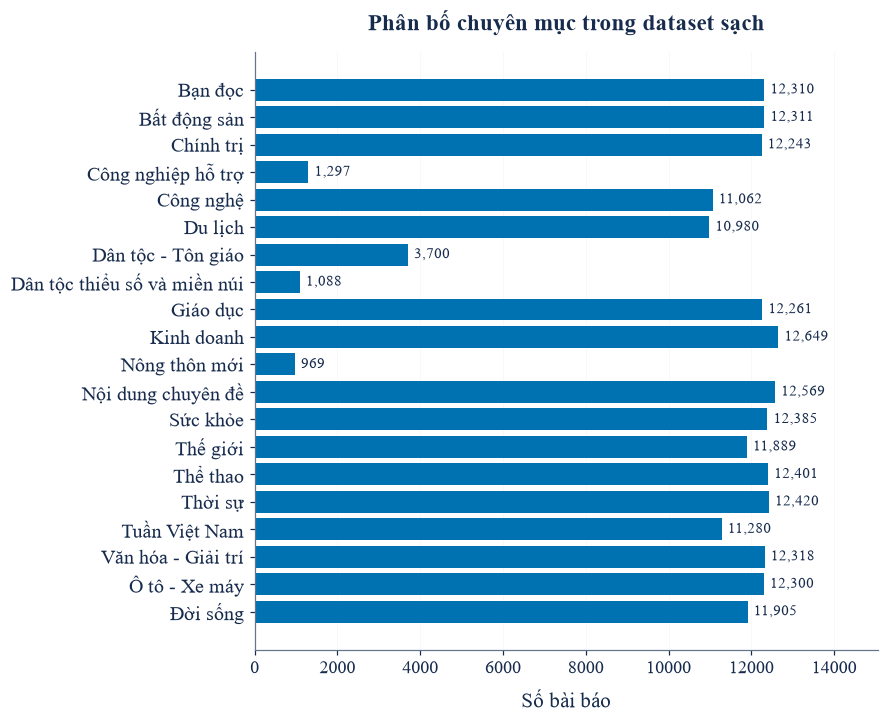

# Phân bố đầu vào: lớp lớn nhất 12,649 bài; lớp nhỏ nhất 969 bài; tỷ lệ 13.05 lần.


In [10]:
raw_classes = sorted(CATEGORY_LABELS.values())
raw_counts = df_raw.label.value_counts().reindex(raw_classes, fill_value=0)
horizontal_plot(raw_counts.to_numpy(), raw_classes,
                'Phân bố chuyên mục trong dataset sạch', 'Số bài báo',
                'dataset/raw_class_distribution')
log(f'Phân bố đầu vào: lớp lớn nhất {raw_counts.max():,} bài; '
    f'lớp nhỏ nhất {raw_counts.min():,} bài; tỷ lệ {raw_counts.max() / raw_counts.min():.2f} lần.')


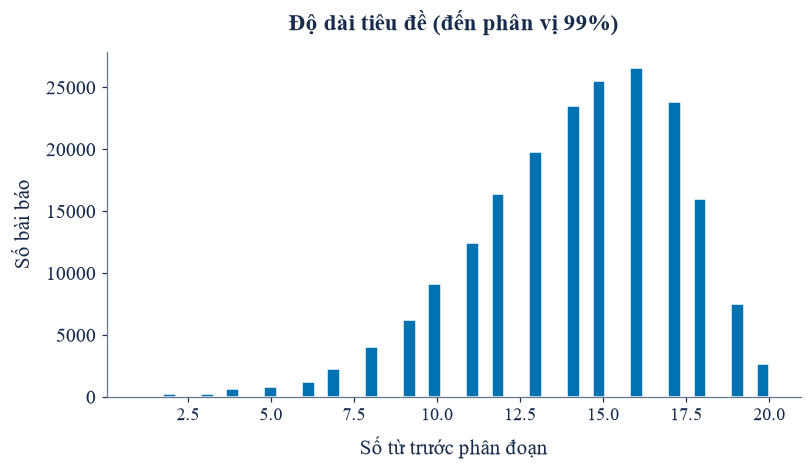

In [11]:
raw_lengths = df_raw['title'].map(lambda text: len(text.split())).to_numpy()
cap = np.quantile(raw_lengths, 0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(raw_lengths[raw_lengths <= cap], bins=50,
        color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số từ trước phân đoạn', ylabel='Số bài báo',
       title='Độ dài tiêu đề (đến phân vị 99%)')
save_fig(fig, 'dataset/raw_title_words_length')


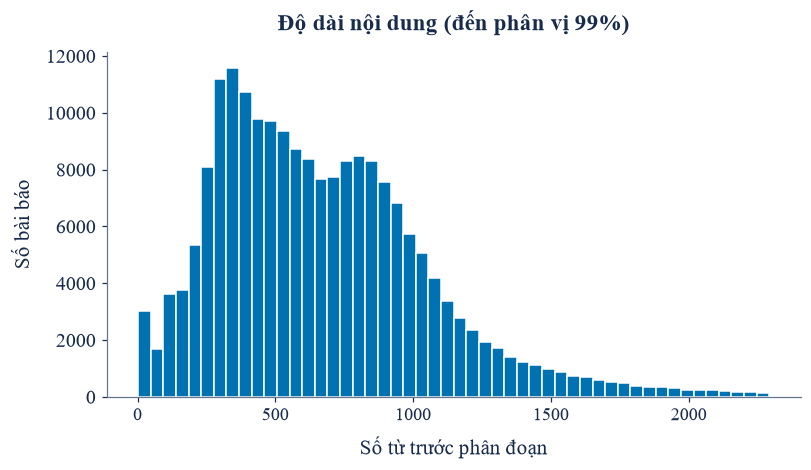

In [12]:
raw_lengths = df_raw['content'].map(lambda text: len(text.split())).to_numpy()
cap = np.quantile(raw_lengths, 0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(raw_lengths[raw_lengths <= cap], bins=50,
        color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số từ trước phân đoạn', ylabel='Số bài báo',
       title='Độ dài nội dung (đến phân vị 99%)')
save_fig(fig, 'dataset/raw_content_words_length')


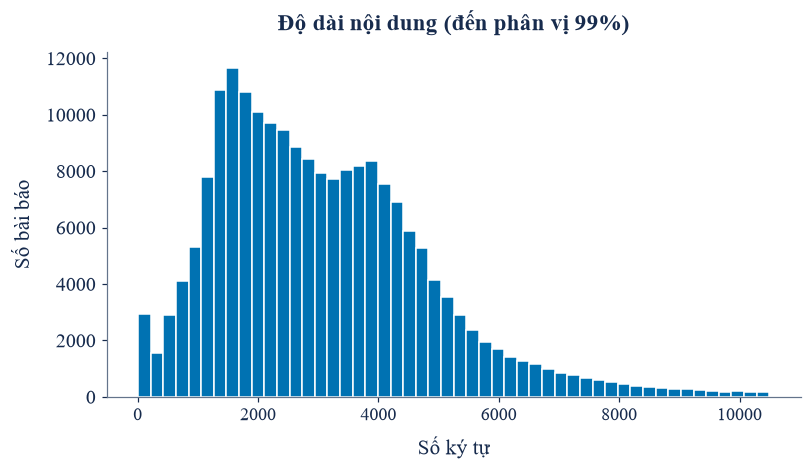

In [13]:
raw_lengths = df_raw['content'].map(len).to_numpy()
cap = np.quantile(raw_lengths, 0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(raw_lengths[raw_lengths <= cap], bins=50,
        color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số ký tự', ylabel='Số bài báo',
       title='Độ dài nội dung (đến phân vị 99%)')
save_fig(fig, 'dataset/raw_content_characters_length')


In [14]:
raw_statistics = []
for label in raw_classes:
    lengths_for_class = df_raw.loc[df_raw.label == label, 'content'].map(lambda text: len(text.split()))
    raw_statistics.append({
        'Nhãn': label, 'Số bài': len(lengths_for_class),
        'Tỷ lệ (%)': 100 * len(lengths_for_class) / len(df_raw),
        'Trung bình số từ': lengths_for_class.mean(),
        'Trung vị số từ': lengths_for_class.median(),
        'Phân vị 95%': lengths_for_class.quantile(0.95),
    })
raw_statistics = pd.DataFrame(raw_statistics)
raw_statistics.to_csv(EVALUATION_DIR / 'raw_dataset_statistics.csv', index=False, encoding='utf-8-sig')
display(raw_statistics.round(2))


,Nhãn,Số bài,Tỷ lệ (%),Trung bình số từ,Trung vị số từ,Phân vị 95%
0,Bạn đọc,12310,6.14,677.25,662.0,1179.00
1,Bất động sản,12311,6.15,740.08,765.0,1175.00
2,Chính trị,12243,6.11,936.46,813.0,2042.90
3,Công nghiệp hỗ trợ,1297,0.65,786.84,711.0,1528.20
4,Công nghệ,11062,5.52,789.20,772.0,1358.95
5,Du lịch,10980,5.48,597.20,537.0,1261.05
6,Dân tộc - Tôn giáo,3700,1.85,928.91,833.0,1862.30
7,Dân tộc thiểu số và miền núi,1088,0.54,578.74,543.0,1150.15
8,Giáo dục,12261,6.12,644.00,594.0,1215.00
9,Kinh doanh,12649,6.31,787.99,782.0,1311.00


## Tiền xử lý văn bản

Ghép tiêu đề và nội dung, chuyển chữ thường, thay dấu câu và chữ số,
phân đoạn bằng PyVi rồi chuẩn hóa khoảng trắng. Không loại stopwords.
Mỗi tiến trình xử lý có tokenizer riêng; dữ liệu đã xử lý được lưu để tái sử dụng.

Loại văn bản rỗng sau chuẩn hóa. Với văn bản giống nhau nhưng khác nhãn, loại toàn bộ
nhóm xung đột; với văn bản trùng cùng nhãn, giữ một bài. Thực hiện trước khi chia tập
để cùng một văn bản không xuất hiện ở cả train và test.


In [15]:
started = time.perf_counter()
cache_path = TEMP_DIR / 'canonical_text.parquet'
cache_signature_path = TEMP_DIR / 'canonical_signature.json'
cache_valid = (cache_path.is_file() and cache_signature_path.is_file() and
               json.loads(cache_signature_path.read_text(encoding='utf-8')).get('signature')
               == source_signature)
if cache_valid:
    canonical = pd.read_parquet(cache_path)
    if len(canonical) != len(df_raw) or not np.array_equal(
        canonical.article_index.to_numpy(), np.arange(len(df_raw))
    ):
        raise RuntimeError('Cache văn bản không khớp corpus đầu vào.')
    log('Nạp cache văn bản có fingerprint phù hợp.')
else:
    canonical = pd.DataFrame({'article_index': np.arange(len(df_raw))})
    canonical['clean_text'] = segment_parallel(
        (df_raw.title + ' ' + df_raw.content).tolist(), 'Phân đoạn từ tiếng Việt')
    canonical.to_parquet(cache_path, index=False)
    write_json(cache_signature_path, {'signature': source_signature})
df = canonical.assign(label=df_raw.label.to_numpy())
df = df.loc[df.clean_text.str.strip() != ''].copy()
ambiguous = df.groupby('clean_text')['label'].transform('nunique') > 1
conflicting_count = int(ambiguous.sum())
df = df.loc[~ambiguous]
before_dedup = len(df)
df = df.drop_duplicates('clean_text').reset_index(drop=True)
duplicate_count = before_dedup - len(df)
df_raw = df_raw.iloc[df.article_index.to_numpy()].reset_index(drop=True)
classes = sorted(CATEGORY_LABELS.values())
label2id = {label: index for index, label in enumerate(classes)}
N_CLASSES = len(classes)
if set(df.label) != set(classes) or df.label.value_counts().min() < 7:
    raise RuntimeError('Mỗi lớp cần ít nhất bảy văn bản chuẩn hóa khác nhau.')
labels = df.label.map(label2id).to_numpy(dtype=np.int64)
corpus_signature = fingerprint({
    'source': source_signature, 'article_indices': df.article_index.tolist(),
    'clean_hashes': pd.util.hash_pandas_object(df.clean_text, index=False).tolist(),
})
preprocessing_seconds = time.perf_counter() - started
del canonical
write_json(EVALUATION_DIR / 'dataset_audit.json', {
    'source_count': sum(dataset_audit['after'].values()), 'corpus_count': len(df),
    'conflicting_label_rows_removed': conflicting_count,
    'same_label_duplicate_rows_removed': duplicate_count,
    'class_counts': {label: int((df.label == label).sum()) for label in classes},
    'source_signature': source_signature, 'corpus_signature': corpus_signature,
})
log(f'Corpus: {len(df):,} bài; loại {conflicting_count:,} bài xung đột nhãn và '
    f'{duplicate_count:,} bản trùng cùng nhãn.')


# Phân đoạn từ tiếng Việt: [########################] 200,337/200,337 (100.0%) | 507 giây | 395.4 mục/giây

# Corpus: 199,965 bài; loại 8 bài xung đột nhãn và 364 bản trùng cùng nhãn.


In [16]:
example = df_raw.iloc[0]
source_text = (example.title + ' ' + example.content).strip()
display(pd.DataFrame([
    {'Giai đoạn': 'Văn bản đầu vào', 'Trích đoạn': source_text[:500]},
    {'Giai đoạn': 'Chữ thường, dấu câu và chữ số', 'Trích đoạn': prepare_text(source_text)[:500]},
    {'Giai đoạn': 'Phân đoạn từ và chuẩn hóa khoảng trắng', 'Trích đoạn': segmented_text(source_text)[:500]},
]))


,Giai đoạn,Trích đoạn
0,Văn bản đầu vào,"1 triệu trang phục UNIQLO tặng trẻ em, nạn nhâ..."
1,"Chữ thường, dấu câu và chữ số",triệu trang phục uniqlo tặng trẻ em nạn nhâ...
2,Phân đoạn từ và chuẩn hóa khoảng trắng,triệu trang_phục uniqlo tặng trẻ_em nạn_nhân t...


---
## Tokenize Head-Tail và chia train, validation và test

**Chiến lược Head-Tail**: lấy một nửa số từ ở đầu và một nửa ở cuối khi bài báo
vượt giới hạn 256/512 từ. LSTM sử dụng ID từ của vocabulary, gồm `<PAD>` và `<UNK>`.
Cách làm này giữ thông tin ở cả phần mở đầu lẫn phần kết của bài báo dài.

Chia phân tầng 70/15/15 sau khi loại văn bản trùng; ba tập không giao nhau theo URL,
văn bản gốc hoặc văn bản sạch. Mỗi tập có đủ 20 nhãn. Vocabulary và các tham số
biểu diễn chỉ được học từ train; validation/test giữ phân bố tự nhiên.


In [17]:
train_indices, holdout_indices = train_test_split(
    np.arange(len(df)), test_size=VAL_SIZE + TEST_SIZE,
    random_state=RANDOM_STATE, stratify=df.label)
val_indices, test_indices = train_test_split(
    holdout_indices, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE, stratify=df.label.iloc[holdout_indices])
split_indices = {'train': train_indices, 'validation': val_indices, 'test': test_indices}
split_names = {'train': 'Huấn luyện', 'validation': 'Validation', 'test': 'Test'}
raw_hashes = pd.util.hash_pandas_object(df_raw.title + ' ' + df_raw.content, index=False).to_numpy()
leakage_rows = []
assert np.array_equal(np.sort(np.concatenate(list(split_indices.values()))), np.arange(len(df)))
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    for name, keys in [('URL', df_raw.url), ('Văn bản gốc', raw_hashes),
                       ('Văn bản chuẩn hóa', df.clean_text)]:
        first = np.asarray(keys)[split_indices[left]]
        second = np.asarray(keys)[split_indices[right]]
        overlap = len(set(first) & set(second))
        leakage_rows.append({'left': left, 'right': right, 'key': name, 'overlap': overlap})
        if overlap:
            raise RuntimeError('Rò rỉ dữ liệu giữa các tập; kiểm tra corpus trước khi huấn luyện.')
for name, indices in split_indices.items():
    assert set(labels[indices]) == set(range(N_CLASSES)), f'Tập {name} thiếu nhãn.'
y_train, y_val, y_test = [labels[indices] for indices in split_indices.values()]
train_class_counts = np.bincount(y_train, minlength=N_CLASSES)
split_signature = fingerprint({'corpus': corpus_signature,
                               'indices': {name: indices.tolist() for name, indices in split_indices.items()}})
split_manifest = {
    'seed': RANDOM_STATE,
    'requested_ratios': {'train': TRAIN_SIZE, 'validation': VAL_SIZE, 'test': TEST_SIZE},
    'counts': {name: len(indices) for name, indices in split_indices.items()},
    'indices': {name: indices.tolist() for name, indices in split_indices.items()},
    'urls_sha256': {name: fingerprint(df_raw.url.iloc[indices].tolist())
                    for name, indices in split_indices.items()},
    'corpus_signature': corpus_signature, 'split_signature': split_signature,
    'deduplication': 'clean_text; conflicting labels removed; identical texts kept once',
    'selection_split': 'validation', 'calibration_fit_split': 'validation',
    'evaluation_split': 'test', 'pairwise_disjoint': True,
}
write_json(EVALUATION_DIR / 'split_manifest.json', split_manifest)
write_json(EVALUATION_DIR / 'leakage_audit.json', leakage_rows)
write_json(MODEL_DIR / 'labels.json', {'classes': classes, 'label2id': label2id})
log(f'Train {len(y_train):,} | Validation {len(y_val):,} | Test {len(y_test):,}.')
log(f'Tỷ lệ lớp nhiều nhất/ít nhất trong train: '
    f'{train_class_counts.max() / train_class_counts.min():.2f} lần.')
display(pd.DataFrame({'ID': np.arange(N_CLASSES), 'Nhãn': classes,
                      'Train': train_class_counts,
                      'Validation': np.bincount(y_val, minlength=N_CLASSES),
                      'Test': np.bincount(y_test, minlength=N_CLASSES)}))


# Train 139,975 | Validation 29,995 | Test 29,995.
# Tỷ lệ lớp nhiều nhất/ít nhất trong train: 13.05 lần.


,ID,Nhãn,Train,Validation,Test
0,0,Bạn đọc,8483,1818,1818
1,1,Bất động sản,8616,1847,1846
2,2,Chính trị,8569,1837,1836
3,3,Công nghiệp hỗ trợ,905,193,194
4,4,Công nghệ,7743,1659,1659
5,5,Du lịch,7685,1647,1647
6,6,Dân tộc - Tôn giáo,2590,555,555
7,7,Dân tộc thiểu số và miền núi,762,163,163
8,8,Giáo dục,8581,1839,1839
9,9,Kinh doanh,8850,1896,1897


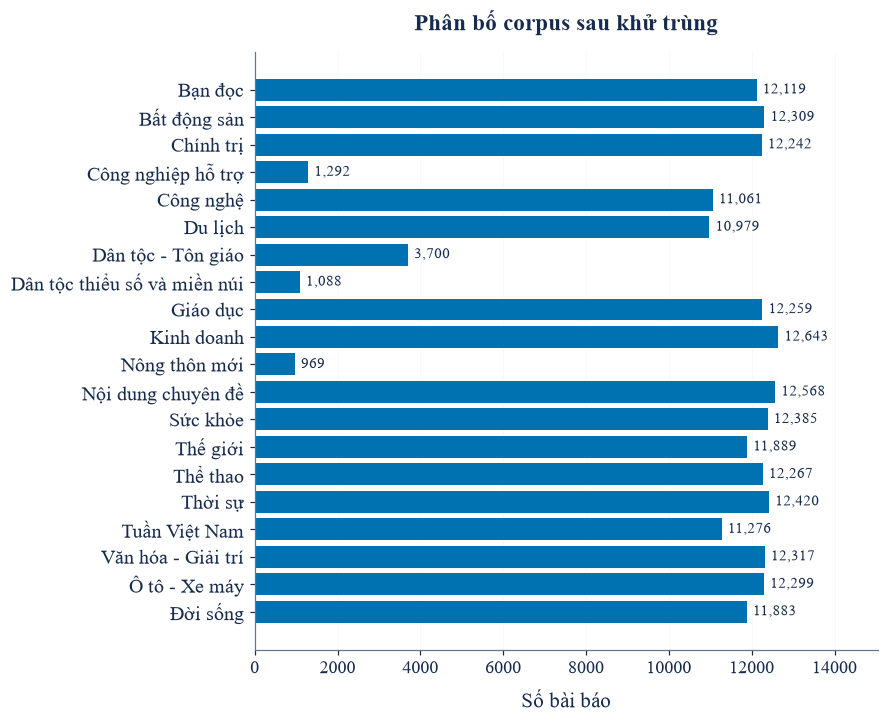

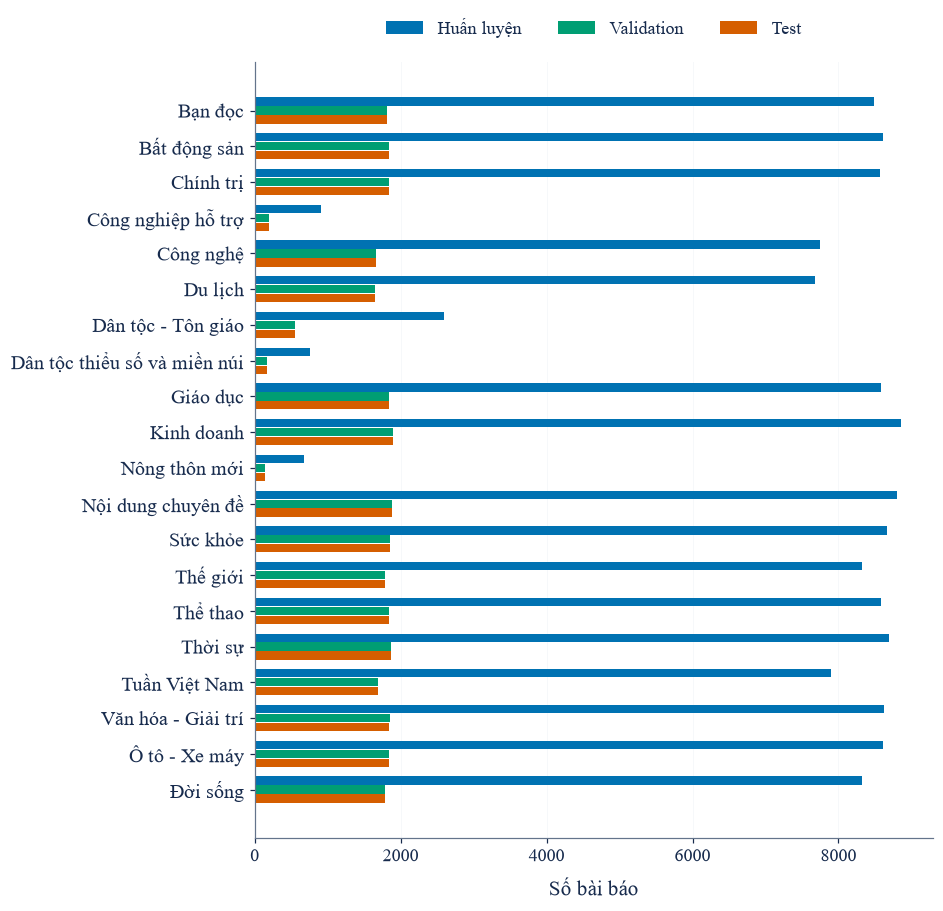

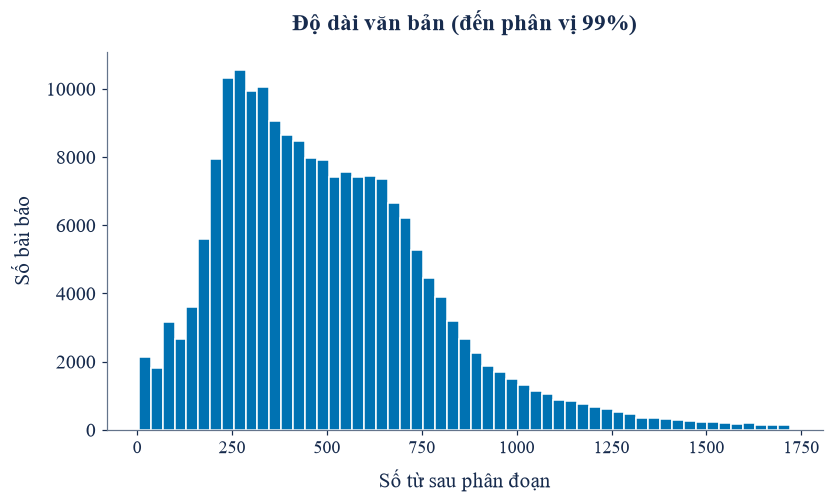

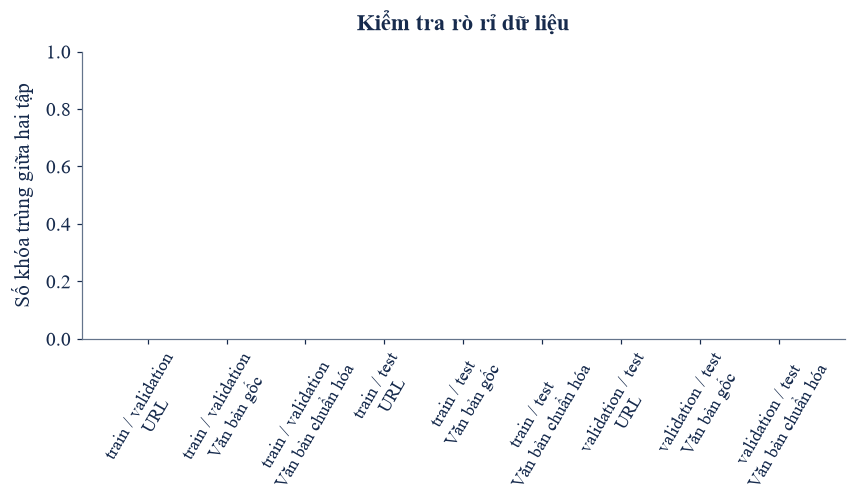

In [18]:
horizontal_plot(np.bincount(labels, minlength=N_CLASSES), classes,
                'Phân bố corpus sau khử trùng', 'Số bài báo', 'dataset/class_distribution')
fig, ax = plt.subplots(figsize=(8.8, 8.5))
positions = np.arange(N_CLASSES)
for offset, name, color in [(-0.25, 'train', 'primary'), (0, 'validation', 'secondary'),
                            (0.25, 'test', 'warning')]:
    ax.barh(positions + offset, np.bincount(labels[split_indices[name]], minlength=N_CLASSES),
            height=0.23, label=split_names[name], color=COLORS[color])
ax.set(yticks=positions, yticklabels=classes, xlabel='Số bài báo')
ax.invert_yaxis()
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False)
ax.grid(axis='x', alpha=0.18)
save_fig(fig, 'dataset/split_distribution')
lengths = df.clean_text.map(lambda text: len(text.split())).to_numpy()
fig, ax = plt.subplots(figsize=(7.8, 4.8))
cap = np.quantile(lengths, 0.99)
ax.hist(lengths[lengths <= cap], bins=55, color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số từ sau phân đoạn', ylabel='Số bài báo',
       title='Độ dài văn bản (đến phân vị 99%)')
save_fig(fig, 'dataset/text_length')
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(np.arange(len(leakage_rows)), [row['overlap'] for row in leakage_rows], color=COLORS['primary'])
ax.set(xticks=np.arange(len(leakage_rows)),
       xticklabels=[f"{row['left']} / {row['right']}\n{row['key']}" for row in leakage_rows],
       ylabel='Số khóa trùng giữa hai tập', ylim=(0, 1), title='Kiểm tra rò rỉ dữ liệu')
ax.tick_params(axis='x', labelrotation=60)
save_fig(fig, 'dataset/split_overlap')


## Vocabulary và kiến trúc mô hình

Vocabulary chỉ đếm từ trên train, giữ tối đa 50.000 token có tần suất từ 2 trở lên,
gồm PAD và UNK. Token không có trong vocabulary được ánh xạ về UNK.
Các từ được sắp theo tần suất giảm dần, rồi theo thứ tự từ điển khi bằng nhau.

BiLSTM gồm embedding 200 chiều học từ đầu, một recurrent layer hai hướng với
128 hidden unit mỗi hướng và lớp tuyến tính 20 nhãn. Ghép trạng thái cuối của hai
hướng thành biểu diễn bài báo. Dropout 0,35 đặt ở embedding và classifier.
Packed sequence bỏ qua padding; mỗi batch chỉ pad đến bài dài nhất trong batch.


In [19]:
import random
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

torch.set_num_threads(CPU_THREADS)
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError('Chọn kernel PyTorch CUDA và GPU NVIDIA trước khi Run All.')
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
TRAIN_DEVICE = torch.cuda.get_device_name(device) if device.type == 'cuda' else 'CPU'
AMP_ENABLED = device.type == 'cuda'
AMP_DTYPE = torch.bfloat16 if AMP_ENABLED and torch.cuda.is_bf16_supported() else torch.float16
torch.backends.cudnn.benchmark = True
if device.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
log('Thiết bị huấn luyện: ' + TRAIN_DEVICE)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(seed)

def amp_context():
    return torch.autocast(device_type='cuda', dtype=AMP_DTYPE) if AMP_ENABLED else nullcontext()

class SequenceDataset(Dataset):
    def __init__(self, encoded, lengths, targets, indices):
        self.encoded, self.lengths, self.targets, self.indices = encoded, lengths, targets, indices
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, item):
        index = int(self.indices[item])
        return self.encoded[index], int(self.lengths[index]), int(self.targets[index])

def collate_sequences(batch):
    lengths = torch.tensor([row[1] for row in batch], dtype=torch.int64)
    width = int(lengths.max())
    input_ids = torch.from_numpy(np.stack([row[0][:width] for row in batch]).astype(np.int64))
    targets = torch.tensor([row[2] for row in batch], dtype=torch.int64)
    return input_ids, lengths, targets

class NewsBiLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, dropout, n_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.embedding_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden_dim, n_classes))
    def forward(self, input_ids, lengths):
        embedded = self.embedding_dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        representation = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.classifier(representation)

def create_model(config):
    return NewsBiLSTM(len(vocabulary), EMBEDDING_DIM, config['hidden_dim'],
                      config['num_layers'], config['dropout'], N_CLASSES).to(device)

def make_loader(encoded, token_lengths, indices, shuffle=False):
    generator = torch.Generator().manual_seed(RANDOM_STATE)
    return DataLoader(SequenceDataset(encoded, token_lengths, labels, indices),
                      batch_size=BATCH_SIZE if shuffle else EVAL_BATCH_SIZE,
                      shuffle=shuffle, num_workers=0, pin_memory=device.type == 'cuda',
                      collate_fn=collate_sequences, generator=generator)

def truncate_ids(ids, max_length):
    if not ids:
        return [1]
    if len(ids) <= max_length:
        return ids
    head = max_length // 2
    return ids[:head] + ids[-(max_length - head):]

def encode_corpus(max_length):
    signature = fingerprint({'corpus': corpus_signature, 'vocabulary': vocabulary_signature,
                              'max_length': max_length, 'strategy': 'head_tail_words'})
    encoded_path = TEMP_DIR / f'tokens_{max_length}.npy'
    lengths_path = TEMP_DIR / f'lengths_{max_length}.npy'
    signature_path = TEMP_DIR / f'tokens_{max_length}_signature.json'
    valid = (encoded_path.is_file() and lengths_path.is_file() and signature_path.is_file() and
             json.loads(signature_path.read_text(encoding='utf-8')).get('signature') == signature)
    if valid:
        encoded = np.load(encoded_path, mmap_mode='r')
        token_lengths = np.load(lengths_path)
    else:
        encoded = np.lib.format.open_memmap(encoded_path, mode='w+', dtype=np.int32,
                                            shape=(len(df), max_length))
        encoded[:] = 0
        token_lengths = np.zeros(len(df), dtype=np.int32)
        for index, text in enumerate(TextProgress(df.clean_text, desc=f'Mã hóa tối đa {max_length} từ')):
            ids = truncate_ids([vocabulary.get(token, 1) for token in text.split()], max_length)
            encoded[index, :len(ids)] = ids
            token_lengths[index] = len(ids)
        encoded.flush()
        np.save(lengths_path, token_lengths)
        write_json(signature_path, {'signature': signature})
        del encoded
        encoded = np.load(encoded_path, mmap_mode='r')
    if (encoded.shape != (len(df), max_length) or token_lengths.shape != (len(df),) or
        np.any(token_lengths < 1) or np.any(token_lengths > max_length)):
        raise RuntimeError('Tensor cache không khớp corpus hoặc cấu hình độ dài.')
    return encoded, token_lengths

@torch.inference_mode()
def predict_loader(model, loader, description, loss_weights=None):
    model.eval()
    outputs = []
    numerator = denominator = 0.0
    with TextProgress(total=len(loader.dataset), desc=description) as progress:
        for input_ids, token_lengths, targets in loader:
            input_ids = input_ids.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            with amp_context():
                logits = model(input_ids, token_lengths)
            if not torch.isfinite(logits).all():
                raise RuntimeError('Model tạo logit không hữu hạn.')
            outputs.append(logits.float().cpu().numpy())
            if loss_weights is not None:
                numerator += float(nn.functional.cross_entropy(
                    logits.float(), targets, weight=loss_weights, reduction='sum').item())
                denominator += float(loss_weights[targets].sum().item())
            progress.update(len(targets))
    return np.concatenate(outputs), numerator / max(denominator, 1e-12)

def save_state(model, path):
    pending = path.with_suffix('.pt.tmp')
    torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, pending)
    os.replace(pending, path)

def train_candidate(config, candidate_id, initial_state=None, previous_history=None):
    set_seed(RANDOM_STATE)
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    encoded, token_lengths = encode_corpus(config['max_length'])
    train_loader = make_loader(encoded, token_lengths, train_indices, shuffle=True)
    val_loader = make_loader(encoded, token_lengths, val_indices)
    model = create_model(config)
    if initial_state is not None:
        model.load_state_dict(initial_state)
    weights = torch.tensor(class_weights(config['class_weight_alpha']), dtype=torch.float32, device=device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['learning_rate'],
                                  weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=0, threshold=EARLY_STOPPING_MIN_DELTA,
        threshold_mode='abs', min_lr=1e-5)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED and AMP_DTYPE == torch.float16)
    history = list(previous_history or [])
    offset = max([row['epoch'] for row in history], default=0)
    best_macro = stopping_reference = -1.0
    best_rank = (-1.0, -1.0, -1.0)
    best_epoch, patience = offset, 0
    checkpoint = TEMP_DIR / f'candidate_{candidate_id}.pt'
    if initial_state is not None:
        initial_scores, _ = predict_loader(model, val_loader, 'Validation checkpoint đầu vào', weights)
        initial_metrics = metrics(y_val, initial_scores.argmax(1))
        best_macro = stopping_reference = initial_metrics['f1_macro']
        best_rank = (initial_metrics['f1_macro'], initial_metrics['f1_weighted'], initial_metrics['accuracy'])
        best_epoch = int(config.get('best_epoch', offset))
        scheduler.step(initial_metrics['f1_macro'])
        save_state(model, checkpoint)
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_started = time.perf_counter()
        learning_rate = float(optimizer.param_groups[0]['lr'])
        model.train()
        numerator = denominator = 0.0
        with TextProgress(total=len(y_train), desc=f'Cấu hình {candidate_id} — epoch {offset + epoch}') as progress:
            for input_ids, token_lengths, targets in train_loader:
                input_ids = input_ids.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with amp_context():
                    logits = model(input_ids, token_lengths)
                    loss_sum = nn.functional.cross_entropy(logits.float(), targets,
                                                            weight=weights, reduction='sum')
                    weight_sum = weights[targets].sum()
                    loss = loss_sum / weight_sum
                if not torch.isfinite(loss):
                    raise RuntimeError('Loss không hữu hạn; dừng để bảo vệ checkpoint.')
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                norm = nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP, error_if_nonfinite=True)
                scaler.step(optimizer)
                scaler.update()
                numerator += float(loss_sum.detach().item())
                denominator += float(weight_sum.detach().item())
                progress.update(len(targets), details=f'Loss {loss.item():.4f}')
        scores, validation_loss = predict_loader(model, val_loader,
                                                  f'Validation epoch {offset + epoch}', weights)
        values = metrics(y_val, scores.argmax(1))
        rank = (values['f1_macro'], values['f1_weighted'], values['accuracy'])
        history.append({'epoch': offset + epoch, 'train_loss': numerator / denominator,
                        'validation_loss': validation_loss, **{'validation_' + key: value
                                                               for key, value in values.items()},
                        'learning_rate': learning_rate,
                        'epoch_seconds': time.perf_counter() - epoch_started,
                        'last_gradient_norm': float(norm.item())})
        if rank > best_rank:
            best_rank, best_macro, best_epoch = rank, values['f1_macro'], offset + epoch
            save_state(model, checkpoint)
        if values['f1_macro'] > stopping_reference + EARLY_STOPPING_MIN_DELTA:
            stopping_reference = values['f1_macro']
            patience = 0
        else:
            patience += 1
        scheduler.step(values['f1_macro'])
        log(f'Epoch {offset + epoch}: train loss {numerator / denominator:.4f}; '
            f'validation loss {validation_loss:.4f}; Macro-F1 {values["f1_macro"]:.4f}.')
        if patience >= EARLY_STOPPING_PATIENCE:
            log('Early stopping: validation không cải thiện đủ ngưỡng trong hai epoch liên tiếp.')
            break
    training_seconds = time.perf_counter() - started
    peak_memory = torch.cuda.max_memory_allocated(device) / 1024 ** 3 if device.type == 'cuda' else 0.0
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    best_scores, best_loss = predict_loader(model, val_loader, 'Validation checkpoint tốt nhất', weights)
    record = {'candidate': candidate_id, 'config': config, 'best_epoch': best_epoch,
              'epochs_this_run': len(history) - len(previous_history or []),
              'validation': metrics(y_val, best_scores.argmax(1)), 'validation_loss': best_loss,
              'fit_seconds': training_seconds, 'gpu_peak_allocated_gib': peak_memory}
    checkpoint.unlink()
    del optimizer, train_loader, val_loader, encoded
    return model, best_scores, record, history


# Thiết bị huấn luyện: NVIDIA RTX A3000 12GB Laptop GPU


In [20]:
vocabulary_path = MODEL_DIR / 'vocabulary.json'
vocabulary_cache = TEMP_DIR / 'vocabulary.json'
vocabulary_cache_meta = TEMP_DIR / 'vocabulary_signature.json'
vocabulary_source_signature = fingerprint({'split': split_signature, 'min_frequency': MIN_TOKEN_FREQUENCY,
                                          'max_vocabulary': MAX_VOCAB_SIZE})
valid = (vocabulary_cache.is_file() and vocabulary_cache_meta.is_file() and
         json.loads(vocabulary_cache_meta.read_text(encoding='utf-8')).get('signature')
         == vocabulary_source_signature)
if valid:
    vocabulary = json.loads(vocabulary_cache.read_text(encoding='utf-8'))
else:
    counts = Counter()
    for text in TextProgress(df.clean_text.iloc[train_indices], desc='Tạo vocabulary từ train'):
        counts.update(text.split())
    tokens = [token for token, count in sorted(counts.items(), key=lambda item: (-item[1], item[0]))
               if count >= MIN_TOKEN_FREQUENCY][:MAX_VOCAB_SIZE - 2]
    vocabulary = {'<PAD>': 0, '<UNK>': 1, **{token: i + 2 for i, token in enumerate(tokens)}}
    write_json(vocabulary_cache, vocabulary)
    write_json(vocabulary_cache_meta, {'signature': vocabulary_source_signature})
    del counts, tokens
vocabulary_signature = fingerprint(vocabulary)
run_signature = fingerprint({'split': split_signature, 'vocabulary': vocabulary_signature,
                              'embedding_dim': EMBEDDING_DIM, 'model': MODEL_KEY})
if TRAINING_MODE in {'continue', 'evaluate'}:
    if not vocabulary_path.is_file():
        raise FileNotFoundError('Chưa có vocabulary/model; chọn fresh.')
    if json.loads(vocabulary_path.read_text(encoding='utf-8')) != vocabulary:
        raise RuntimeError('Vocabulary model không khớp train hiện tại; chọn fresh.')
log(f'Vocabulary chỉ fit train: {len(vocabulary):,} token, gồm PAD và UNK.')


# Tạo vocabulary từ train: [########################] 139,975/139,975 (100.0%) | 15 giây | 9551.4 mục/giây

# Vocabulary chỉ fit train: 50,000 token, gồm PAD và UNK.


## Huấn luyện mô hình

BiLSTM được huấn luyện với weighted cross-entropy; trọng số class tính từ tập train.

| Thiết lập | Giá trị |
|---|---|
| Optimizer | AdamW |
| Learning rate ban đầu | 0,001 |
| Batch train / kiểm định | 64 / 128 |
| Số epoch tối đa | 10 mỗi cấu hình |
| Early stopping | Macro-F1, patience 2, cải thiện tối thiểu 0,001 |
| Scheduler | Giảm learning rate một nửa sau một epoch không cải thiện đủ 0,001 |
| Learning rate tối thiểu | 0,00001 |
| Weight decay / clip gradient norm | 0,0001 / 1,0 |
| Kiểm định và lưu checkpoint | Mỗi epoch |
| Checkpoint dùng đánh giá | Macro-F1 validation tốt nhất |
| Precision | BF16 nếu GPU hỗ trợ; FP16 trên GPU còn lại |

| Cấu hình | Số từ tối đa | Số mũ trọng số lớp |
|---|---|---|
| Head–Tail 256 | 256 | 0,5 |
| Head–Tail 512 | 512 | 0,5 |
| Head–Tail 512 balanced | 512 | 1,0 |

Trọng số `(N_train / (20 × n_class)) ** alpha` được chuẩn hóa để trung bình theo
tần suất train bằng 1. Số lượng được tính lại sau tiền xử lý, loại trùng và chia tập.
Sampler ngẫu nhiên giữ phân bố thật; validation/test không được cân bằng lại.

Mỗi cấu hình khởi tạo cùng seed. Validation chọn cấu hình theo Macro-F1,
rồi Weighted-F1 và Accuracy khi bằng nhau. Test không tham gia chọn checkpoint.
Early stopping theo ngưỡng cải thiện 0,001; checkpoint vẫn giữ điểm validation tốt nhất.

Mô hình chỉ được nạp để train tiếp khi dữ liệu, tiền xử lý, vocabulary và cả ba tập
khớp fingerprint. Mỗi lượt khởi tạo optimizer/scheduler mới, cộng tối đa 10 epoch
vào lịch sử và giữ checkpoint đầu vào nếu các epoch mới không cải thiện.


In [21]:
checkpoint_path = MODEL_DIR / 'checkpoint.pt'
selected_config_path = MODEL_DIR / 'selected_config.json'
history_path = EVALUATION_DIR / 'training_history.json'
search_records = []
search_started = time.perf_counter()
if TRAINING_MODE in {'continue', 'evaluate'}:
    if not checkpoint_path.is_file() or not selected_config_path.is_file():
        raise FileNotFoundError('Chưa có checkpoint tương thích; chọn fresh.')
    selected_config = json.loads(selected_config_path.read_text(encoding='utf-8'))
    if selected_config['run_signature'] != run_signature or selected_config['classes'] != classes:
        raise RuntimeError('Checkpoint không khớp corpus, split hoặc kiến trúc; chọn fresh.')
    initial_state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    timing = json.loads((MODEL_DIR / 'timing.json').read_text(encoding='utf-8'))
    if TRAINING_MODE == 'continue':
        previous_history = json.loads(history_path.read_text(encoding='utf-8')) if history_path.is_file() else []
        log('Tiếp tục trọng số với optimizer/scheduler mới; giữ lịch sử epoch và checkpoint tốt nhất.')
        best_model, validation_scores, record, selected_history = train_candidate(
            selected_config, 1, initial_state, previous_history)
        selected_config['best_epoch'] = record['best_epoch']
        timing = {**timing,
                  'selected_fit_seconds': timing['selected_fit_seconds'] + record['fit_seconds'],
                  'continuation_seconds': timing.get('continuation_seconds', 0.0) + record['fit_seconds']}
        save_state(best_model, checkpoint_path)
        write_json(selected_config_path, selected_config)
        write_json(history_path, selected_history)
        write_json(MODEL_DIR / 'timing.json', timing)
    else:
        best_model = create_model(selected_config)
        best_model.load_state_dict(initial_state)
        selected_history = json.loads(history_path.read_text(encoding='utf-8')) if history_path.is_file() else []
        encoded, token_lengths = encode_corpus(selected_config['max_length'])
        validation_scores, _ = predict_loader(best_model, make_loader(encoded, token_lengths, val_indices),
                                               'Dự đoán validation')
        del encoded
    del initial_state
else:
    best_rank = (-1.0, -1.0, -1.0)
    best_model = None
    for candidate_id, config in enumerate(CANDIDATES, start=1):
        log(f'Cấu hình {candidate_id}/{len(CANDIDATES)}: {config["max_length"]} từ, '
            f'trọng số lớp lũy thừa {config["class_weight_alpha"]}.')
        candidate_model, scores, record, history = train_candidate(config, candidate_id)
        search_records.append(record)
        write_json(EVALUATION_DIR / 'search_results.json', search_records)
        values = record['validation']
        rank = (values['f1_macro'], values['f1_weighted'], values['accuracy'])
        if rank > best_rank:
            best_rank = rank
            if best_model is not None:
                del best_model
            best_model = candidate_model
            validation_scores = scores
            selected_history = history
            selected_config = {**config, 'embedding_dim': EMBEDDING_DIM,
                               'vocabulary_size': len(vocabulary), 'max_epochs': MAX_EPOCHS,
                               'batch_size': BATCH_SIZE, 'early_stopping_patience': EARLY_STOPPING_PATIENCE,
                               'early_stopping_min_delta': EARLY_STOPPING_MIN_DELTA,
                               'weight_decay': WEIGHT_DECAY, 'gradient_clip': GRADIENT_CLIP,
                               'scheduler_factor': 0.5, 'scheduler_patience': 0,
                               'seed': RANDOM_STATE, 'classes': classes,
                               'vocabulary_signature': vocabulary_signature, 'run_signature': run_signature,
                               'best_epoch': record['best_epoch'],
                               'gpu_peak_allocated_gib': record['gpu_peak_allocated_gib'],
                               'amp': 'bf16' if AMP_ENABLED and AMP_DTYPE == torch.bfloat16
                                      else 'fp16' if AMP_ENABLED else 'fp32',
                               'parameter_count': sum(parameter.numel() for parameter in best_model.parameters())}
            selected_fit_seconds = record['fit_seconds']
            save_state(best_model, checkpoint_path)
        else:
            del candidate_model
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    if best_model is None:
        raise RuntimeError('Không có cấu hình LSTM được huấn luyện.')
    timing = {'search_seconds': time.perf_counter() - search_started,
              'selected_fit_seconds': selected_fit_seconds,
              'inference_scope': 'DataLoader + host-to-device transfer + model forward; excludes segmentation/encoding'}
    write_json(vocabulary_path, vocabulary)
    write_json(selected_config_path, selected_config)
    write_json(history_path, selected_history)
    write_json(MODEL_DIR / 'timing.json', timing)
write_json(MODEL_DIR / 'class_weights.json', {
    'fit_split': 'train', 'alpha': selected_config['class_weight_alpha'],
    'formula': '(N_train / (N_classes * n_class)) ** alpha, weighted mean normalized to 1',
    'train_counts': train_class_counts.tolist(),
    'weights': class_weights(selected_config['class_weight_alpha']).tolist(),
})
log(f'Checkpoint được chọn: epoch {selected_config["best_epoch"]}; '
    f'Macro-F1 validation {metrics(y_val, validation_scores.argmax(1))["f1_macro"]:.4f}.')
display_configuration(selected_config)


# Cấu hình 1/3: 256 từ, trọng số lớp lũy thừa 0.5.


# Mã hóa tối đa 256 từ: [########################] 199,965/199,965 (100.0%) | 25 giây | 7901.5 mục/giây

# Cấu hình 1 — epoch 1: [########################] 139,975/139,975 (100.0%) | 95 giây | 1476.5 mục/giây | Loss 0.7121

# Validation epoch 1: [########################] 29,995/29,995 (100.0%) | 4 giây | 7485.6 mục/giây

# Epoch 1: train loss 1.2487; validation loss 0.6666; Macro-F1 0.7550.


...

# Validation epoch 10: [########################] 29,995/29,995 (100.0%) | 9 giây | 3431.1 mục/giây

# Epoch 10: train loss 0.2502; validation loss 0.5325; Macro-F1 0.8403.


# Validation checkpoint tốt nhất: [########################] 29,995/29,995 (100.0%) | 9 giây | 3425.3 mục/giây

# Checkpoint được chọn: epoch 10; Macro-F1 validation 0.8449.


,Tham số,Giá trị
0,Cấu hình,head tail 512 sqrt
1,Số từ đầu vào tối đa,512
2,Hidden mỗi hướng,128
3,Số recurrent layer,1
4,Dropout,0.35
5,Learning rate,0.001
6,Số mũ trọng số lớp,0.5
7,Chiều embedding,200
8,Kích thước vocabulary,50000
9,Giới hạn epoch mỗi lượt,10


---
## Đánh giá mô hình

Tạo báo cáo phân loại, ma trận nhầm lẫn và chỉ số Accuracy, Macro-F1, Weighted-F1
trên test độc lập. Chỉ cấu hình được chọn bằng validation đi qua bước này.
Temperature được fit trên validation rồi giữ cố định trước khi dự đoán test.
Khoảng tin cậy 95% dùng bootstrap test cho một mô hình cố định, không thay thế
thực nghiệm nhiều seed.


In [22]:
# Temperature chỉ được ước lượng trên validation, không dùng nhãn test.
def validation_nll(log_temperature):
    scaled = np.asarray(validation_scores, dtype=np.float64) / np.exp(log_temperature)
    return float(np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(y_val)), y_val]))
fit = minimize_scalar(validation_nll, bounds=(np.log(0.05), np.log(20.0)), method='bounded')
if not fit.success or not np.isfinite(fit.fun):
    raise RuntimeError('Không tìm được temperature hợp lệ từ validation.')
temperature = float(np.exp(fit.x))
if validation_nll(0.0) < fit.fun:
    temperature = 1.0
write_json(MODEL_DIR / 'calibration.json', {
    'temperature': temperature, 'fit_split': 'validation',
    'objective': 'negative_log_likelihood', 'decision': 'argmax_raw_scores',
    'probability_source': SCORE_KIND,
})
log(f'Temperature validation: {temperature:.4f}; tham số đã cố định trước đánh giá test.')


# Temperature validation: 1.4685; tham số đã cố định trước đánh giá test.


In [23]:
encoded, token_lengths = encode_corpus(selected_config['max_length'])
if device.type == 'cuda':
    torch.cuda.synchronize(device)
started = time.perf_counter()
test_scores, _ = predict_loader(best_model, make_loader(encoded, token_lengths, test_indices),
                                'Dự đoán test độc lập')
if device.type == 'cuda':
    torch.cuda.synchronize(device)
test_inference_seconds = time.perf_counter() - started
del encoded


# Dự đoán test độc lập: [########################] 29,995/29,995 (100.0%) | 9 giây | 3249.5 mục/giây

In [24]:
test_predictions = np.asarray(test_scores).argmax(axis=1).astype(np.int64)
test_probabilities = temperature_probabilities(test_scores, temperature)
assert np.array_equal(test_predictions, test_probabilities.argmax(axis=1))
test_metrics = metrics(y_test, test_predictions)
before = probability_diagnostics(test_scores, y_test, 1.0)
after = probability_diagnostics(test_scores, y_test, temperature)
report = classification_report(y_test, test_predictions, labels=np.arange(N_CLASSES),
                                target_names=classes, output_dict=True, zero_division=0)
matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(N_CLASSES))
intervals = bootstrap_intervals(y_test, test_predictions)
report_text = classification_report(y_test, test_predictions, labels=np.arange(N_CLASSES),
                                    target_names=classes, digits=4, zero_division=0)
print(report_text)
(RESULT_DIR / 'classification_report.txt').write_text(report_text, encoding='utf-8')
write_json(EVALUATION_DIR / 'classification_report.json', report)
write_json(EVALUATION_DIR / 'confusion_matrix.json', matrix.tolist())
write_json(EVALUATION_DIR / 'confusion_matrix_normalized.json',
           (matrix / np.maximum(matrix.sum(1, keepdims=True), 1)).tolist())
summary = {
    'model': MODEL_NAME, 'model_key': MODEL_KEY, 'selected_config': selected_config,
    'classes': classes, 'selection_split': 'validation', 'evaluation_split': 'test',
    'selection_metric': 'f1_macro', 'validation': metrics(y_val, validation_scores.argmax(axis=1)),
    'before': {**test_metrics, 'nll': before['nll'], 'ece_15_bins': before['ece_15_bins']},
    'after': {**test_metrics, 'nll': after['nll'], 'ece_15_bins': after['ece_15_bins']},
    'temperature': temperature, 'class_decision_adjustment': False,
    'probability_source': SCORE_KIND, 'confidence_intervals_95': intervals,
    'bootstrap': {'resamples': BOOTSTRAP_RESAMPLES, 'method': 'iid_percentile_fixed_model',
                  'seed': RANDOM_STATE},
    'corpus_count': len(df), 'split_counts': split_manifest['counts'],
    'corpus_signature': corpus_signature, 'split_signature': split_signature,
    'test_urls_sha256': split_manifest['urls_sha256']['test'],
    'timing': {**timing, 'preprocessing_seconds': preprocessing_seconds,
               'test_inference_seconds': test_inference_seconds,
               'inference_samples_per_second': len(y_test) / max(test_inference_seconds, 1e-9)},
    'environment': {'python': platform.python_version(), 'platform': platform.platform(),
                    'cpu_threads': CPU_THREADS,
                    'versions': {package: importlib.metadata.version(package)
                                 for package in ENV_PACKAGES}, 'training_device': TRAIN_DEVICE},
}
write_json(EVALUATION_DIR / 'metrics.json', summary)
write_json(EVALUATION_DIR / 'comparison_summary.json', summary)
write_json(EVALUATION_DIR / 'calibration_diagnostics.json', {'before': before, 'after': after})
np.savez_compressed(EVALUATION_DIR / 'test_scores.npz', scores=test_scores, labels=y_test,
                    indices=test_indices)
predictions = pd.DataFrame({
    'url': df_raw.url.iloc[test_indices].to_numpy(), 'corpus_index': test_indices,
    'true_id': y_test, 'predicted_id': test_predictions,
    'true_label': [classes[i] for i in y_test],
    'predicted_label': [classes[i] for i in test_predictions],
    'confidence': test_probabilities[np.arange(len(y_test)), test_predictions],
    'correct': y_test == test_predictions,
})
predictions.to_parquet(EVALUATION_DIR / 'predictions.parquet', index=False)
errors = predictions.loc[~predictions.correct].sort_values('confidence', ascending=False).head(30)
examples = []
for row in errors.to_dict('records'):
    article = df_raw.iloc[int(row['corpus_index'])]
    examples.append({**row, 'title': article.title, 'content_excerpt': article.content[:500]})
write_json(EVALUATION_DIR / 'error_examples.json', examples)
diagnostic_table = pd.DataFrame([
    {'ID': i, 'Nhãn': label, 'Precision': report[label]['precision'],
     'Recall': report[label]['recall'], 'F1': report[label]['f1-score'],
     'Support': int(report[label]['support'])}
    for i, label in enumerate(classes)])
diagnostic_table.to_csv(EVALUATION_DIR / 'per_class_metrics.csv', index=False, encoding='utf-8-sig')
display(diagnostic_table)
log(f'Test {len(y_test):,} bài: Accuracy {test_metrics["accuracy"]:.4f}, '
    f'Macro-F1 {test_metrics["f1_macro"]:.4f}, Weighted-F1 {test_metrics["f1_weighted"]:.4f}.')


                              precision    recall  f1-score   support

                     Bạn đọc     0.9535    0.9362    0.9448      1818
                Bất động sản     0.9137    0.9290    0.9213      1846
                   Chính trị     0.8687    0.8720    0.8703      1836
          Công nghiệp hỗ trợ     0.8387    0.9381    0.8856       194
                   Công nghệ     0.8512    0.8933    0.8718      1659
                     Du lịch     0.8617    0.8780    0.8698      1647
          Dân tộc - Tôn giáo     0.5983    0.6523    0.6241       555
Dân tộc thiểu số và miền núi     0.5182    0.6994    0.5953       163
                    Giáo dục     0.9086    0.9141    0.9114      1839
                  Kinh doanh     0.8663    0.7649    0.8124      1897
               Nông thôn mới     0.3991    0.6096    0.4824       146
          Nội dung chuyên đề     0.7728    0.7289    0.7502      1885
                    Sức khỏe     0.9250    0.9435    0.9342      1857
                   

,ID,Nhãn,Precision,Recall,F1,Support
0,0,Bạn đọc,0.953501,0.936194,0.944768,1818
1,1,Bất động sản,0.913692,0.929036,0.921300,1846
2,2,Chính trị,0.868692,0.872004,0.870345,1836
3,3,Công nghiệp hỗ trợ,0.838710,0.938144,0.885645,194
4,4,Công nghệ,0.851235,0.893309,0.871765,1659
5,5,Du lịch,0.861740,0.877960,0.869774,1647
6,6,Dân tộc - Tôn giáo,0.598347,0.652252,0.624138,555
7,7,Dân tộc thiểu số và miền núi,0.518182,0.699387,0.595300,163
8,8,Giáo dục,0.908649,0.914084,0.911358,1839
9,9,Kinh doanh,0.866269,0.764892,0.812430,1897


# Test 29,995 bài: Accuracy 0.8866, Macro-F1 0.8460, Weighted-F1 0.8871.


---
## Xuất cấu hình mô hình

Lưu mapping nhãn, cấu hình được chọn và temperature trong `model/lstm/` để phục vụ suy luận.
Checkpoint và vocabulary được lưu ở phần huấn luyện.
Nạp lại gói đã xuất và đối chiếu dự đoán trên validation để kiểm tra tính nhất quán.


In [25]:
write_json(MODEL_DIR / 'inference_config.json', {
    'model': MODEL_NAME, 'model_key': MODEL_KEY, 'classes': classes,
    'label2id': label2id, 'selected_config': selected_config,
    'temperature': temperature, 'probability_source': SCORE_KIND,
    'class_decision_adjustment': False, 'run_signature': run_signature,
    'preprocessing': 'title + content; lowercase; punctuation/digits removed; PyVi; whitespace normalized',
})


In [26]:
reloaded_vocabulary = json.loads(vocabulary_path.read_text(encoding='utf-8'))
calibration = json.loads((MODEL_DIR / 'calibration.json').read_text(encoding='utf-8'))
reloaded_model = create_model(selected_config)
reloaded_model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
reloaded_model.eval()
@torch.inference_mode()
def predict_article(title, content):
    text = segmented_text(str(title).strip() + ' ' + str(content).strip())
    ids = truncate_ids([reloaded_vocabulary.get(token, 1) for token in text.split()],
                       selected_config['max_length'])
    inputs = torch.tensor([ids], dtype=torch.int64, device=device)
    with amp_context():
        logits = reloaded_model(inputs, torch.tensor([len(ids)], dtype=torch.int64))
    probabilities = temperature_probabilities(logits.float().cpu().numpy(), calibration['temperature'])[0]
    order = np.argsort(-probabilities, kind='stable')[:3]
    return [{'label': classes[i], 'confidence': float(probabilities[i])} for i in order]
encoded, token_lengths = encode_corpus(selected_config['max_length'])
reloaded_scores, _ = predict_loader(reloaded_model, make_loader(encoded, token_lengths, val_indices[:3]),
                                     'Đối chiếu gói model')
# Cùng batch size để đối chiếu chính xác cả phép tính mixed precision.
original_scores, _ = predict_loader(best_model, make_loader(encoded, token_lengths, val_indices[:3]),
                                     'Đối chiếu pipeline validation')
np.testing.assert_allclose(reloaded_scores, original_scores, rtol=1e-5, atol=1e-5)
del encoded
log('Gói model nạp lại cho logit nhất quán với checkpoint validation.')
display(pd.DataFrame(predict_article(df_raw.iloc[int(val_indices[0])].title,
                                     df_raw.iloc[int(val_indices[0])].content)))


# Đối chiếu gói model: [########################] 3/3 (100.0%) | 0 giây | 95.7 mục/giây

# Đối chiếu pipeline validation: [########################] 3/3 (100.0%) | 0 giây | 105.9 mục/giây

# Gói model nạp lại cho logit nhất quán với checkpoint validation.


,label,confidence
0,Tuần Việt Nam,0.994308
1,Nội dung chuyên đề,0.001907
2,Chính trị,0.000810


## Đánh giá hiệu chỉnh trên test

Temperature dương được tối ưu **chỉ trên validation**, rồi giữ cố định.
Phần này đo NLL và ECE trên test theo `softmax(scores / temperature)`.
Temperature không đổi thứ tự điểm số nên Accuracy, Precision, Recall và F1
trước/sau giống nhau. NLL validation được dùng chọn temperature; NLL hoặc ECE test
không được bảo đảm cải thiện. Không điều chỉnh ngưỡng quyết định riêng cho từng class.


In [27]:
display(pd.DataFrame([
    {'Trạng thái': 'Chưa hiệu chỉnh', **test_metrics,
     'NLL': before['nll'], 'ECE (15 bins)': before['ece_15_bins']},
    {'Trạng thái': 'Temperature', **test_metrics,
     'NLL': after['nll'], 'ECE (15 bins)': after['ece_15_bins']},
]).rename(columns={'accuracy': 'Accuracy', 'f1_macro': 'Macro-F1', 'f1_weighted': 'Weighted-F1'}))
log(f'Temperature validation: {temperature:.4f}; '
    'giữ nguyên quyết định argmax trên test.')


,Trạng thái,Accuracy,Macro-F1,Weighted-F1,NLL,ECE (15 bins)
0,Chưa hiệu chỉnh,0.886648,0.845995,0.887105,0.416339,0.053196
1,Temperature,0.886648,0.845995,0.887105,0.368136,0.011488


# Temperature validation: 1.4685; giữ nguyên quyết định argmax trên test.


---
## Chẩn đoán mô hình

Phần này in ra các tín hiệu quan trọng để phân tích lỗi sau huấn luyện và calibration,
gồm lớp có F1 thấp, mức hỗ trợ và các bài dự đoán sai với độ tin cậy cao.
Các biểu đồ tham số và đặc trưng hỗ trợ diễn giải cấu hình được chọn.


In [28]:
display(diagnostic_table.sort_values(['F1', 'Support'], ascending=[True, True]).head(5))
if examples:
    display(pd.DataFrame(examples)[['title', 'true_label', 'predicted_label', 'confidence', 'url']].head(10)
            .rename(columns={'title': 'Tiêu đề', 'true_label': 'Nhãn đúng',
                             'predicted_label': 'Nhãn dự đoán', 'confidence': 'Độ tin cậy', 'url': 'URL'}))
else:
    log('Không có bài dự đoán sai trong tập test.')


,ID,Nhãn,Precision,Recall,F1,Support
10,10,Nông thôn mới,0.399103,0.609589,0.482385,146
7,7,Dân tộc thiểu số và miền núi,0.518182,0.699387,0.595300,163
6,6,Dân tộc - Tôn giáo,0.598347,0.652252,0.624138,555
11,11,Nội dung chuyên đề,0.772778,0.728912,0.750205,1885
19,19,Đời sống,0.828555,0.794167,0.810997,1783


,Tiêu đề,Nhãn đúng,Nhãn dự đoán,Độ tin cậy,URL
0,Ô tô mới có thể được miễn đăng kiểm lần đầu từ...,Thời sự,Ô tô - Xe máy,0.999946,https://vietnamnet.vn/o-to-moi-co-the-duoc-mie...
1,Ấm lòng với hành động nam thanh niên đi xe máy...,Bạn đọc,Ô tô - Xe máy,0.999820,https://vietnamnet.vn/am-long-voi-hanh-dong-na...
2,Người lính nghèo bị lột da toàn thân vì bỏng nặng,Thời sự,Bạn đọc,0.999643,https://vietnamnet.vn/nguoi-linh-ngheo-bi-lot-...
3,"Dệt may ước ‘ôm’ về 46 tỷ USD, Việt Nam vững t...",Kinh doanh,Công nghiệp hỗ trợ,0.999216,https://vietnamnet.vn/det-may-uoc-om-ve-46-ty-...
4,Xem trọn vẹn giải Copa America 2024 trên ứng d...,Công nghệ,Thể thao,0.998564,https://vietnamnet.vn/xem-tron-ven-giai-copa-a...
5,Danh sách người hâm mộ ủng hộ nghệ sĩ Hán Văn ...,Văn hóa - Giải trí,Bạn đọc,0.998175,https://vietnamnet.vn/danh-sach-nguoi-ham-mo-u...
6,Google tích hợp AI Gemini vào hệ sinh thái sản...,Giáo dục,Công nghệ,0.998060,https://vietnamnet.vn/google-tich-hop-ai-gemin...
7,"Bố mẹ 'căng não' lên lịch trình, xin nghỉ khôn...",Đời sống,Du lịch,0.997117,https://vietnamnet.vn/bo-me-cang-nao-len-lich-...
8,"Lo người sử dụng đất bị thiệt, bạn đọc kiến ng...",Bất động sản,Bạn đọc,0.996639,https://vietnamnet.vn/lo-nguoi-su-dung-dat-bi-...
9,Tổng Bí thư Nguyễn Phú Trọng dâng hương tại Ho...,Dân tộc - Tôn giáo,Chính trị,0.996015,https://vietnamnet.vn/tong-bi-thu-nguyen-phu-t...


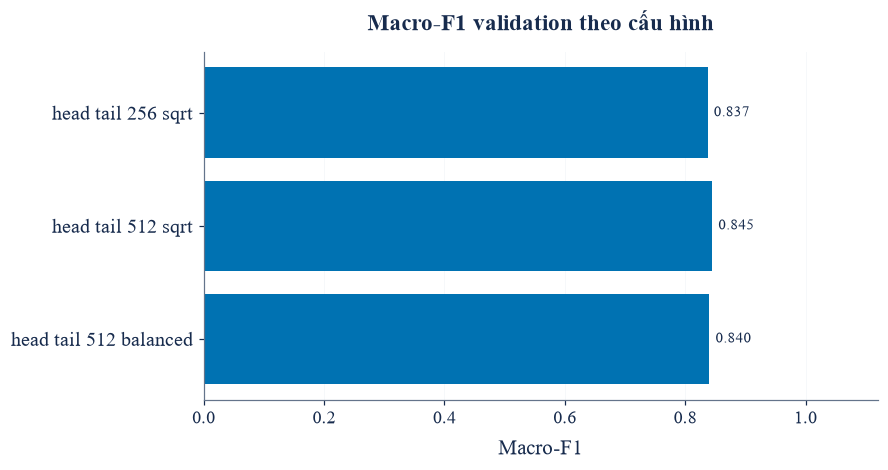

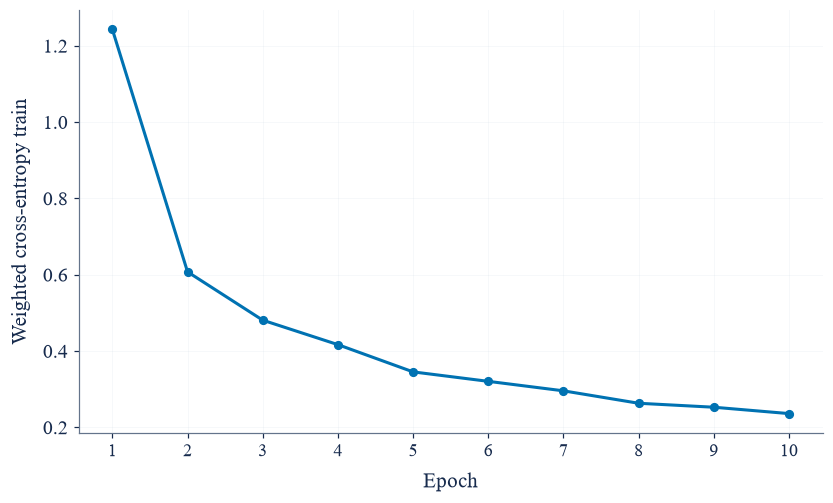

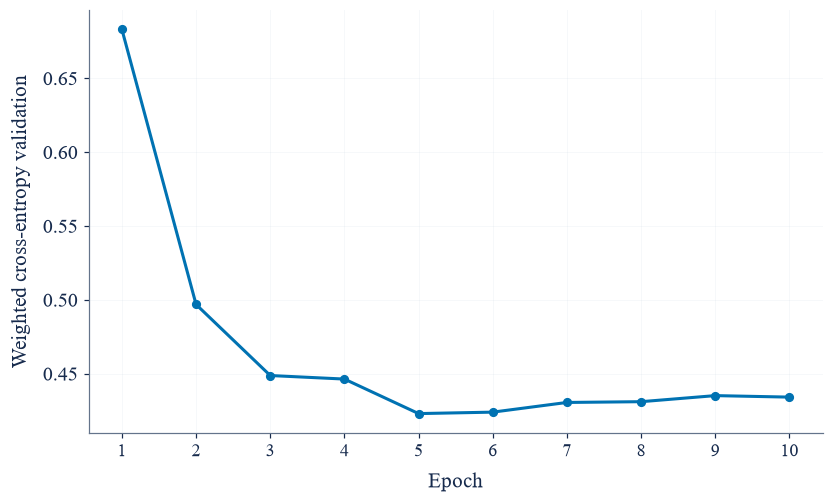

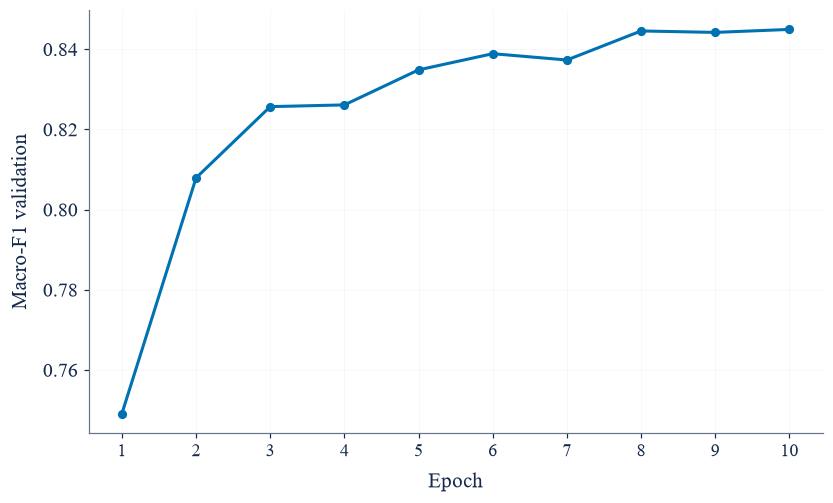

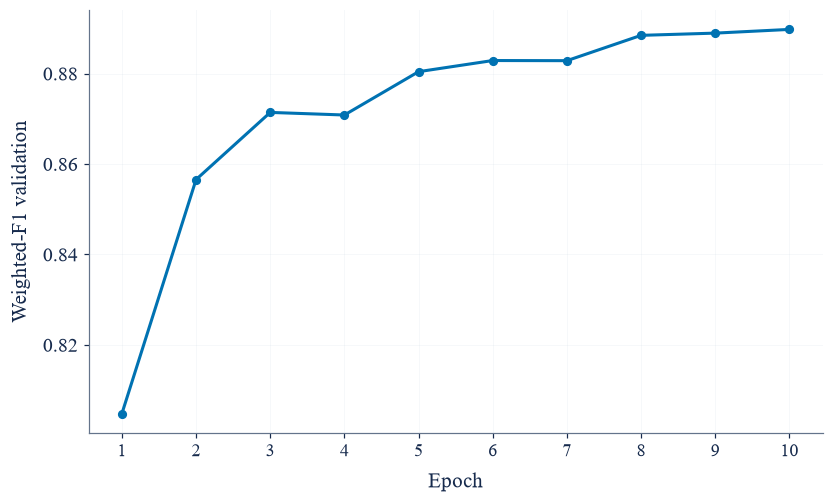

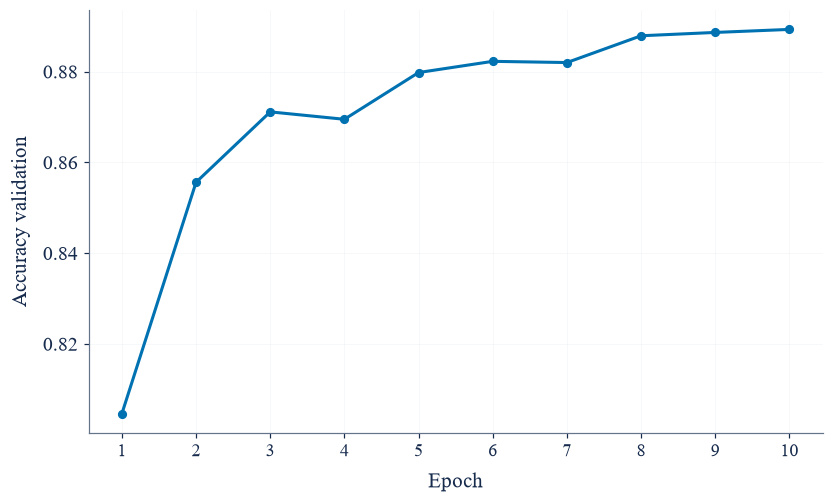

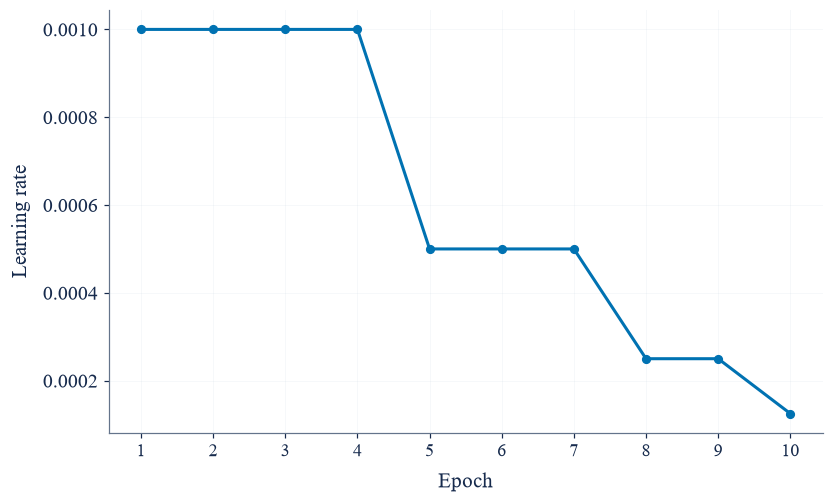

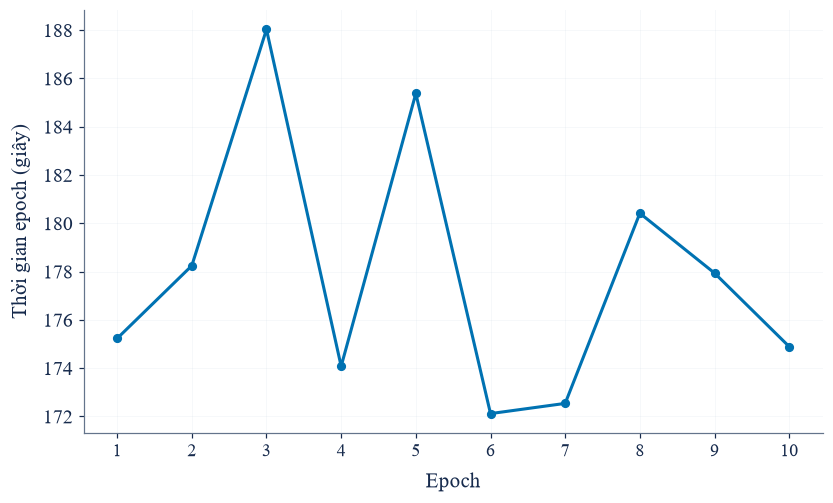

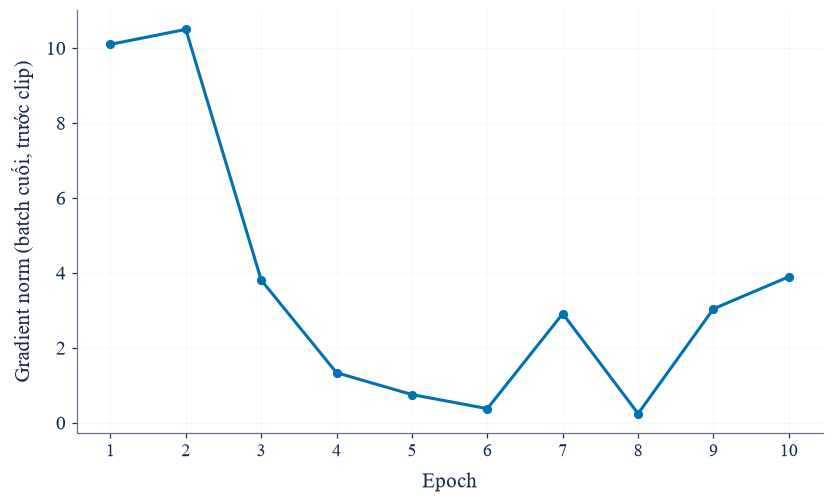

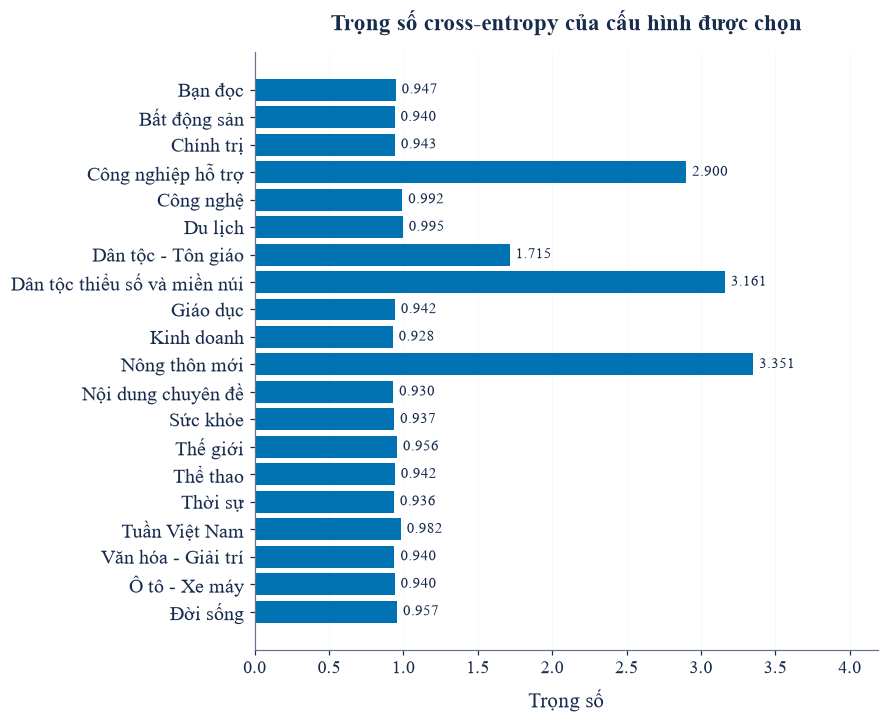

# Đo từ ngoài vocabulary — Huấn luyện: [########################] 139,975/139,975 (100.0%) | 14 giây | 10188.2 mục/giây

# Đo từ ngoài vocabulary — Validation: [########################] 29,995/29,995 (100.0%) | 3 giây | 10409.4 mục/giây

# Đo từ ngoài vocabulary — Test: [########################] 29,995/29,995 (100.0%) | 3 giây | 10215.9 mục/giây

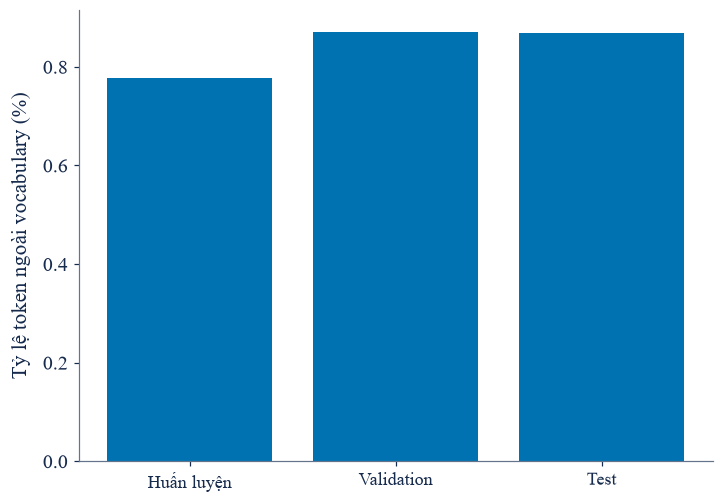

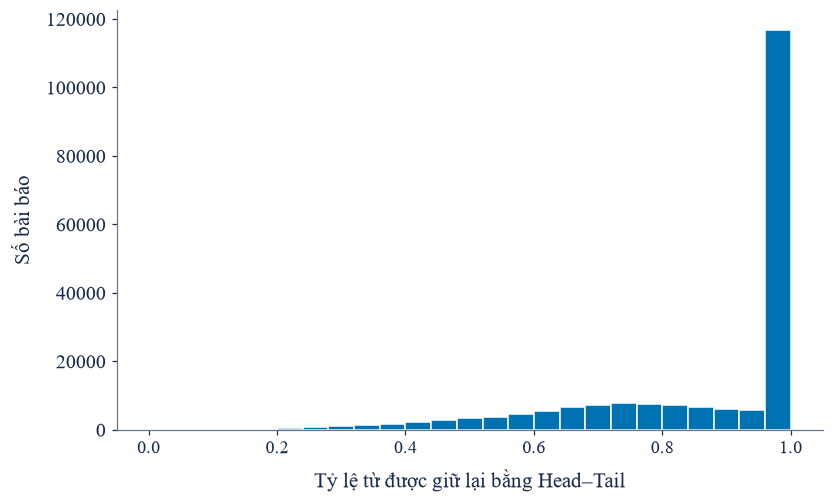

In [29]:
if not search_records and (EVALUATION_DIR / 'search_results.json').is_file():
    search_records = json.loads((EVALUATION_DIR / 'search_results.json').read_text(encoding='utf-8'))
if search_records:
    horizontal_plot(np.array([row['validation']['f1_macro'] for row in search_records]),
                    [row['config']['name'].replace('_', ' ') for row in search_records],
                    'Macro-F1 validation theo cấu hình', 'Macro-F1',
                    'selection/validation_macro_f1', limit=1.12)
for key, ylabel in [('train_loss', 'Weighted cross-entropy train'),
                     ('validation_loss', 'Weighted cross-entropy validation'),
                     ('validation_f1_macro', 'Macro-F1 validation'),
                     ('validation_f1_weighted', 'Weighted-F1 validation'),
                     ('validation_accuracy', 'Accuracy validation'),
                     ('learning_rate', 'Learning rate'), ('epoch_seconds', 'Thời gian epoch (giây)'),
                     ('last_gradient_norm', 'Gradient norm (batch cuối, trước clip)')]:
    fig, ax = plt.subplots(figsize=(7.8, 4.8))
    ax.plot([row['epoch'] for row in selected_history], [row[key] for row in selected_history],
            'o-', color=COLORS['primary'])
    ax.set(xlabel='Epoch', ylabel=ylabel, xticks=[row['epoch'] for row in selected_history])
    ax.grid(alpha=0.18)
    save_fig(fig, 'training/' + key)
horizontal_plot(class_weights(selected_config['class_weight_alpha']), classes,
                'Trọng số cross-entropy của cấu hình được chọn', 'Trọng số',
                'training/class_weights', limit=float(class_weights(selected_config['class_weight_alpha']).max()) * 1.25)
oov_rows = []
for name, indices in split_indices.items():
    unknown = total = 0
    for text in TextProgress(df.clean_text.iloc[indices], desc='Đo từ ngoài vocabulary — ' + split_names[name]):
        tokens = text.split()
        total += len(tokens)
        unknown += sum(token not in vocabulary for token in tokens)
    oov_rows.append({'split': name, 'token_count': total, 'unknown_count': unknown,
                     'oov_rate': unknown / max(total, 1)})
write_json(EVALUATION_DIR / 'vocabulary_audit.json', {
    'fit_split': 'train', 'vocabulary_size': len(vocabulary), 'splits': oov_rows,
    'max_length_words': selected_config['max_length'], 'strategy': 'head_tail_words',
})
fig, ax = plt.subplots(figsize=(6.8, 4.8))
ax.bar([split_names[row['split']] for row in oov_rows],
        [100 * row['oov_rate'] for row in oov_rows], color=COLORS['primary'])
ax.set(ylabel='Tỷ lệ token ngoài vocabulary (%)')
save_fig(fig, 'dataset/oov_rate')
fig, ax = plt.subplots(figsize=(7.8, 4.8))
retained = np.minimum(lengths, selected_config['max_length']) / np.maximum(lengths, 1)
ax.hist(retained, bins=np.linspace(0, 1, 26), color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Tỷ lệ từ được giữ lại bằng Head–Tail', ylabel='Số bài báo')
save_fig(fig, 'dataset/token_retention')


## Xuất kết quả và phân tích trực quan

Kết quả được tính từ dataset, ba tập, lịch sử huấn luyện và logits của lượt thực thi.
Mỗi hình hiển thị và xuất riêng. Ma trận sử dụng ID theo bảng nhãn.
Validation chọn checkpoint và fit tham số hiệu chỉnh; các bảng chỉ số và phân tích lỗi
bên dưới sử dụng **test độc lập**. Đường Precision–Recall đánh giá từng class theo
cơ chế một-chống-phần-còn-lại; không thay thế quyết định phân loại đa lớp.


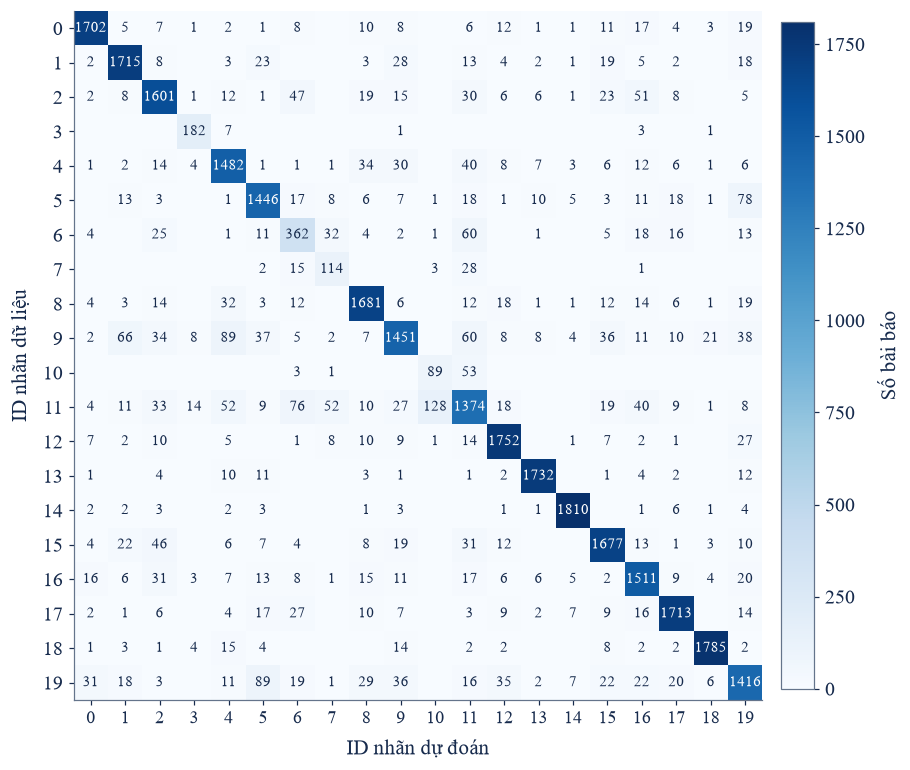

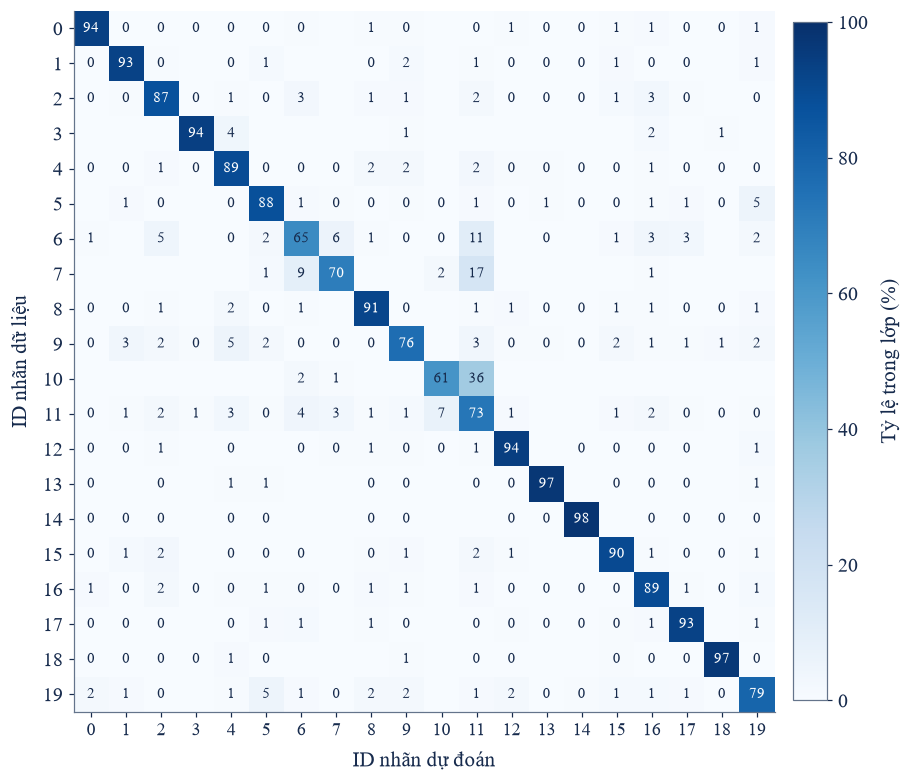

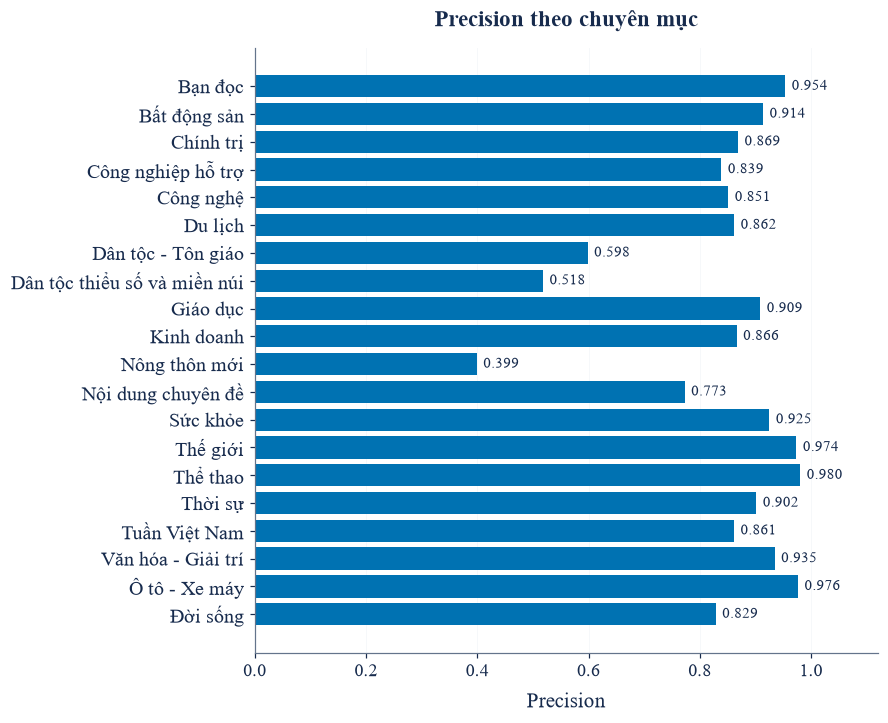

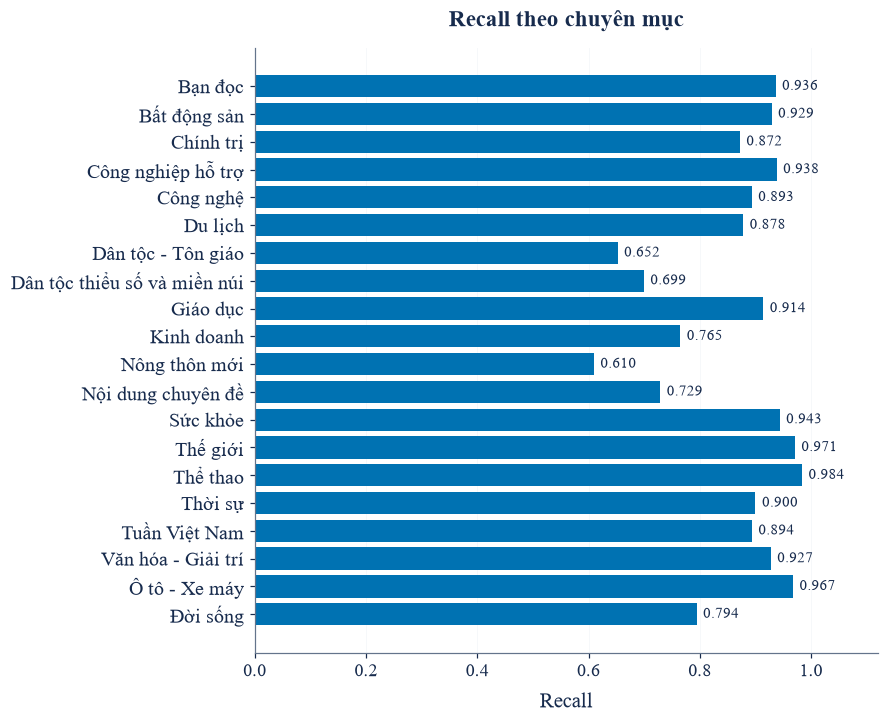

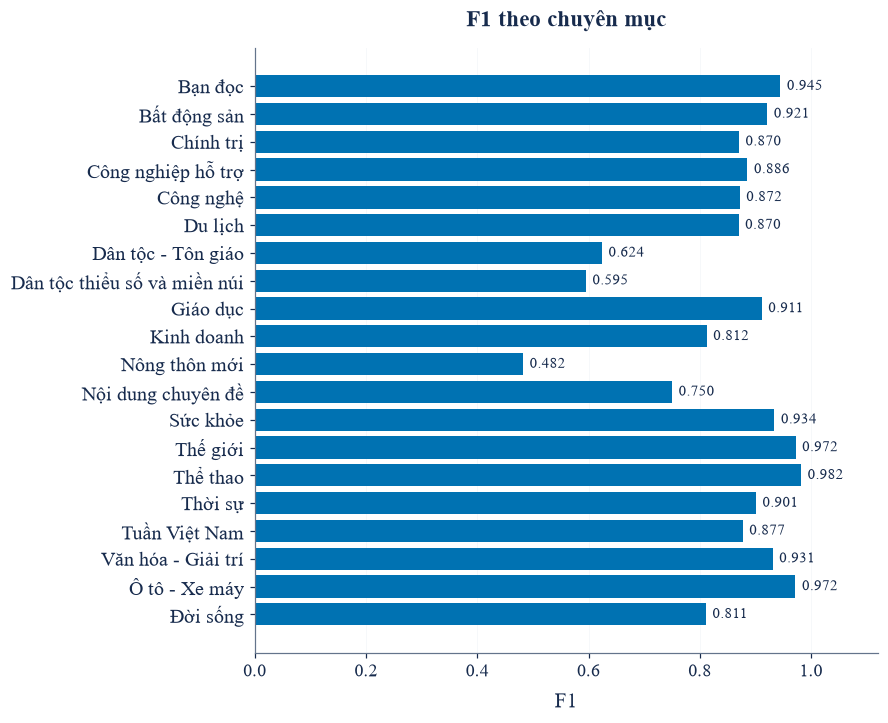

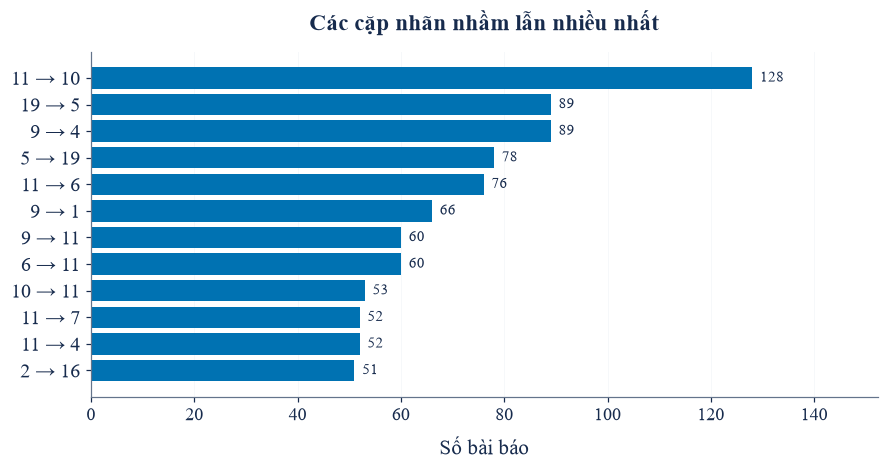

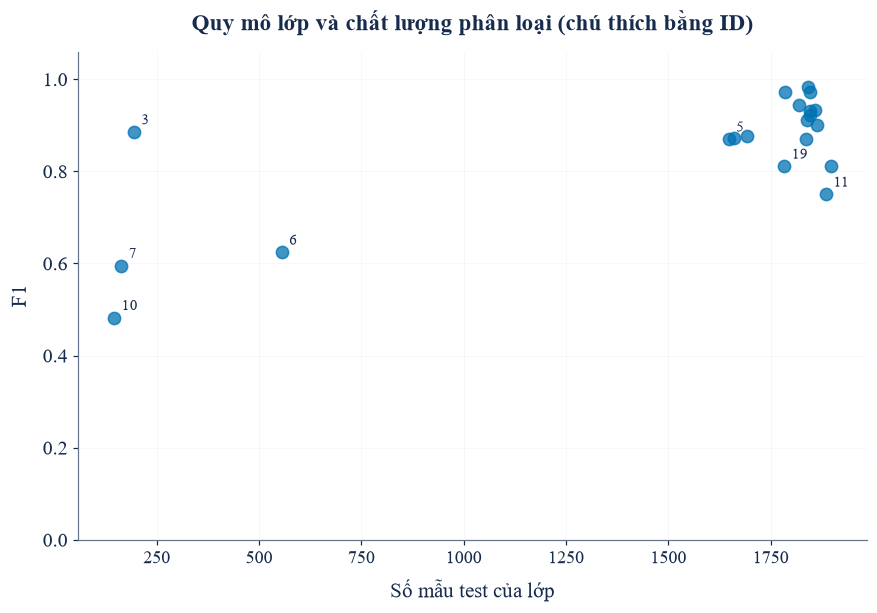

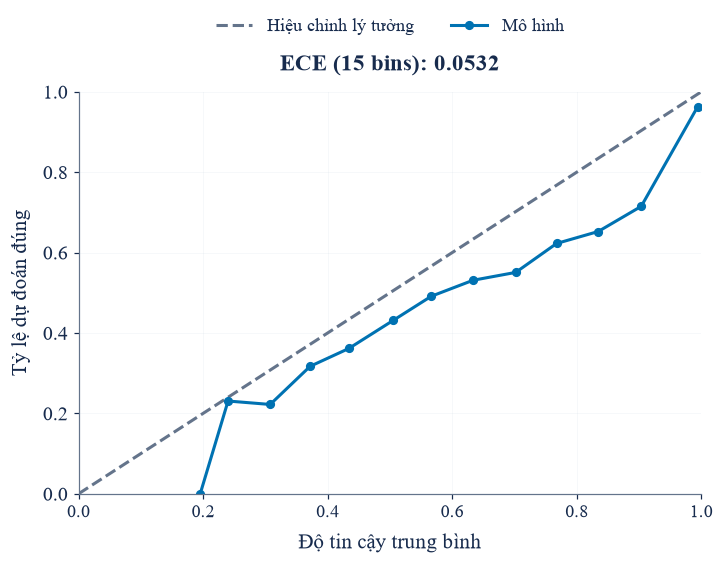

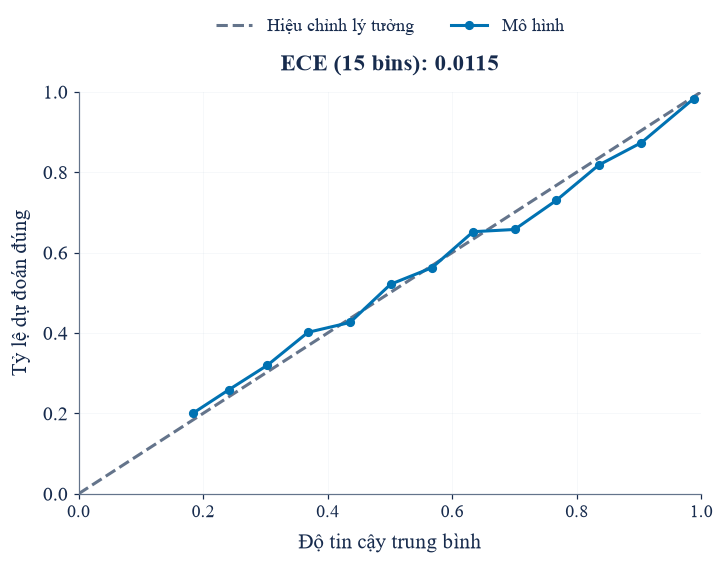

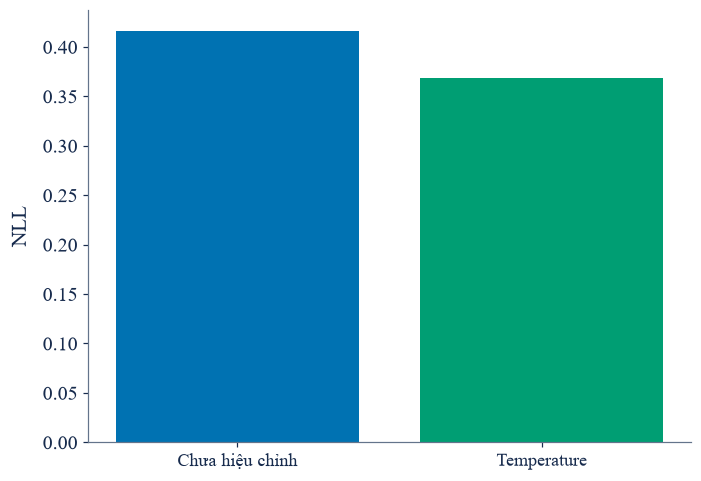

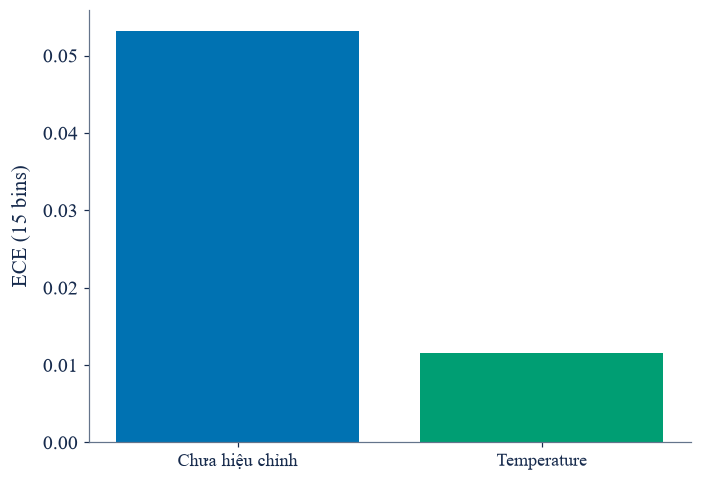

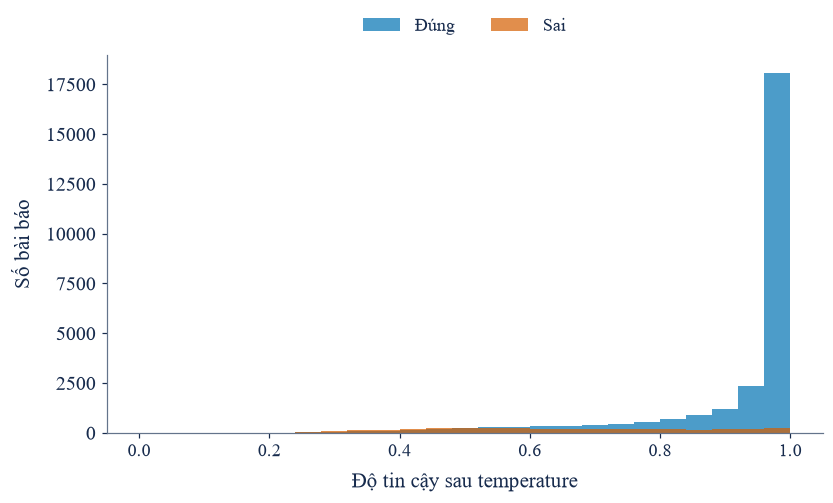

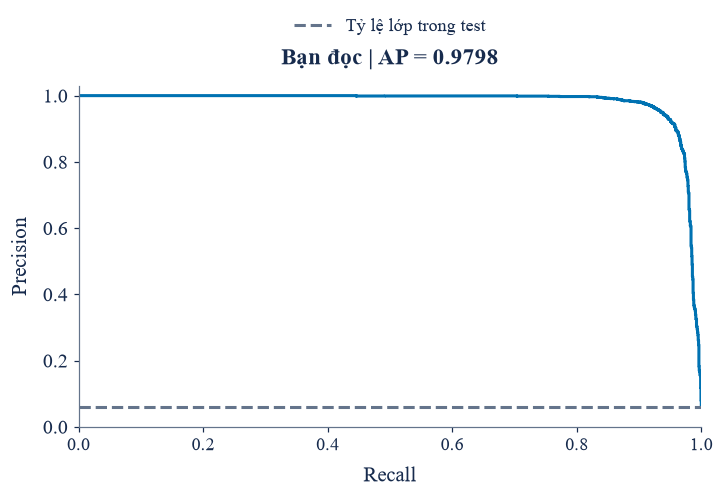

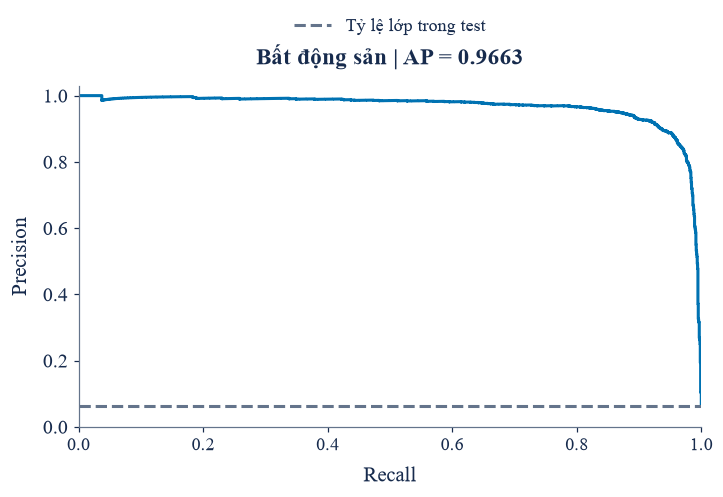

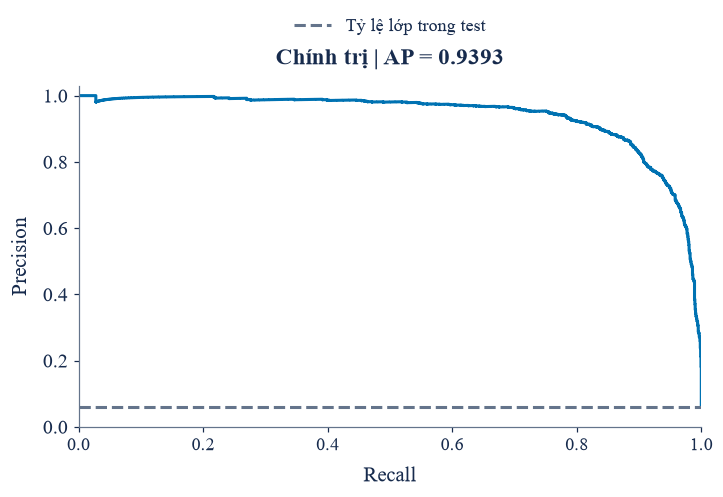

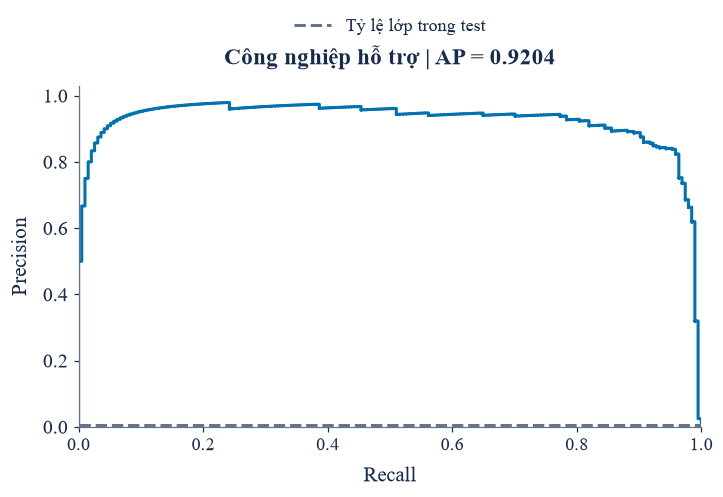

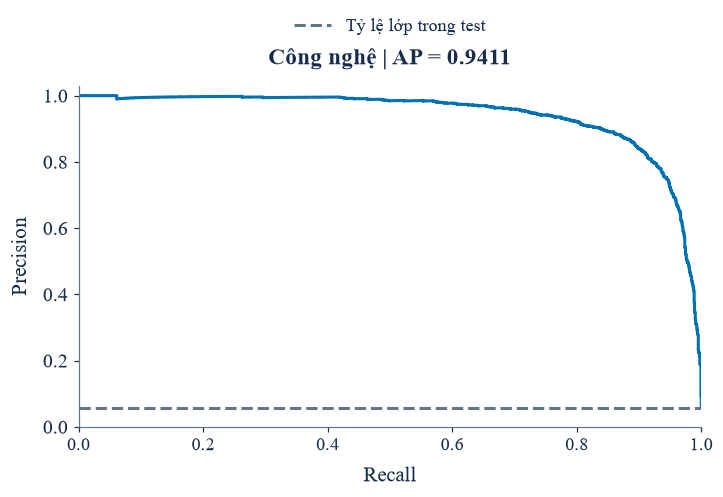

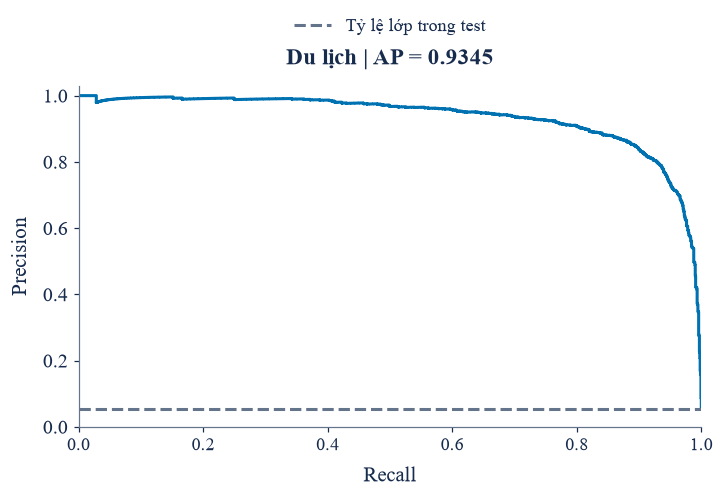

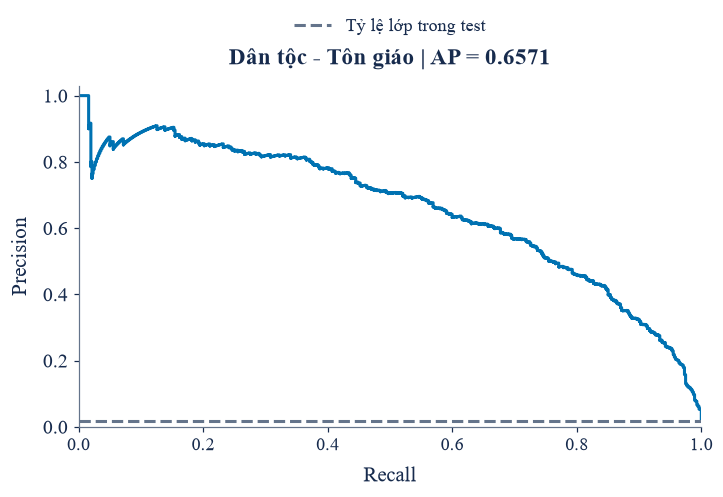

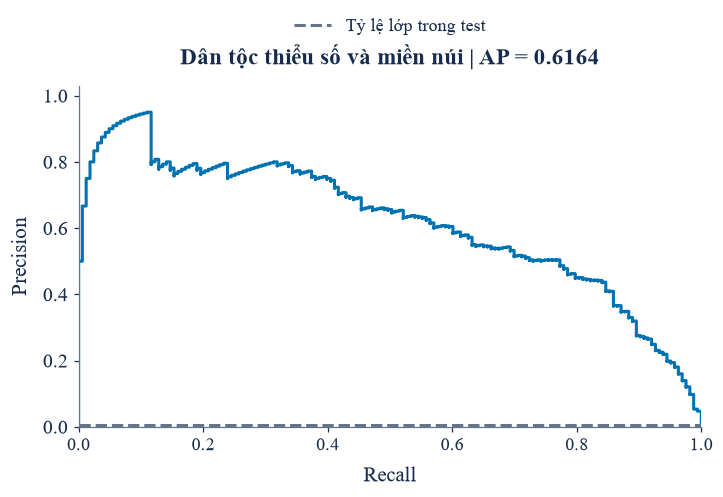

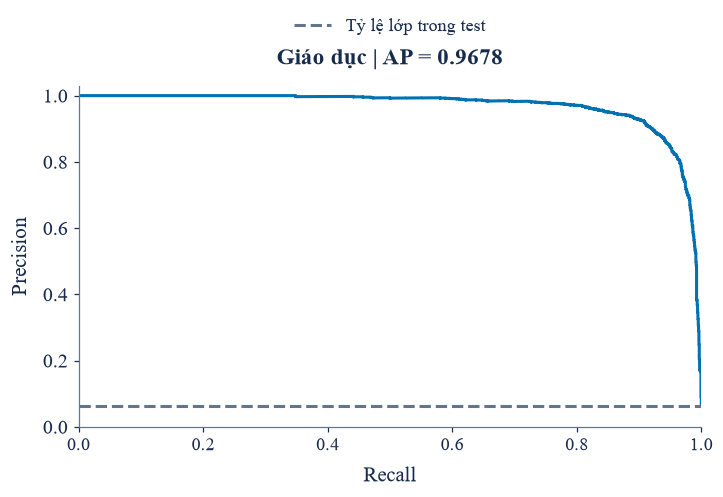

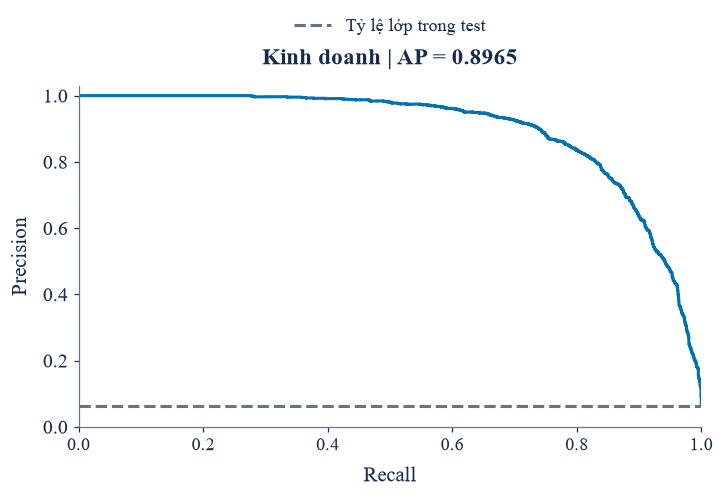

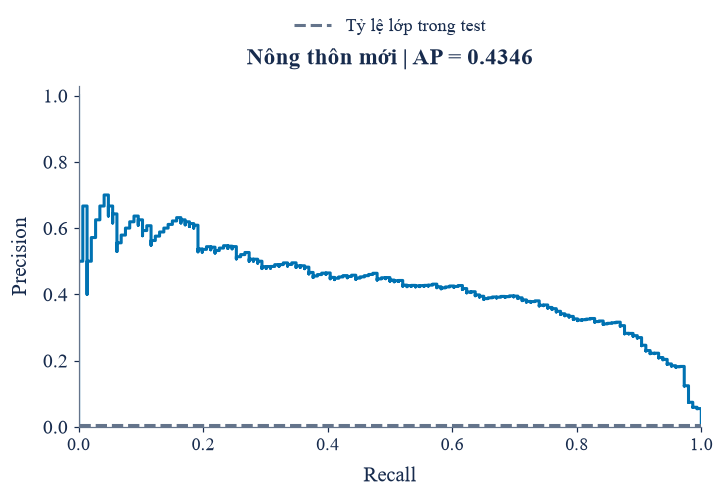

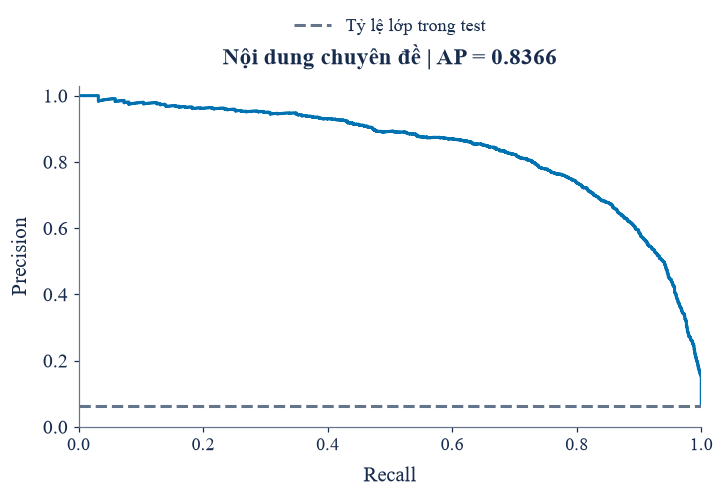

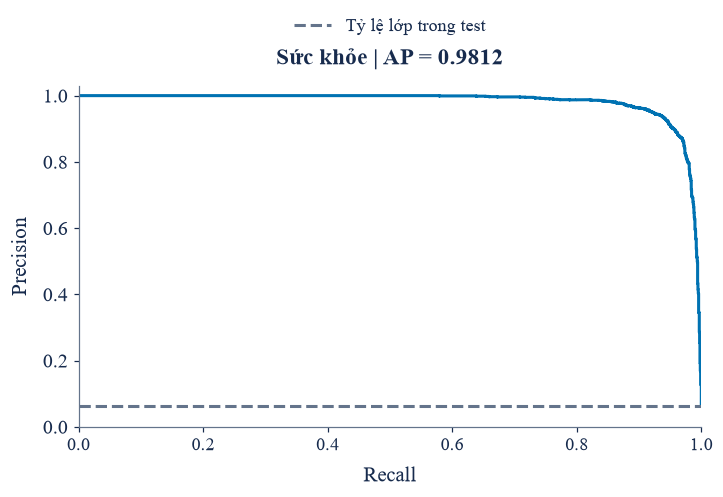

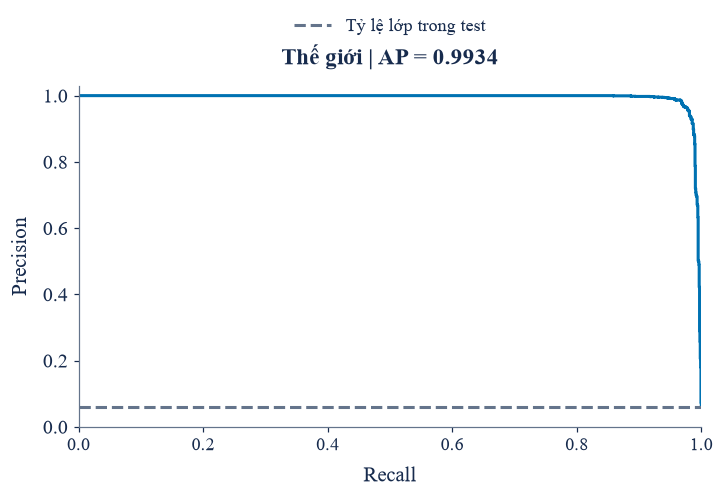

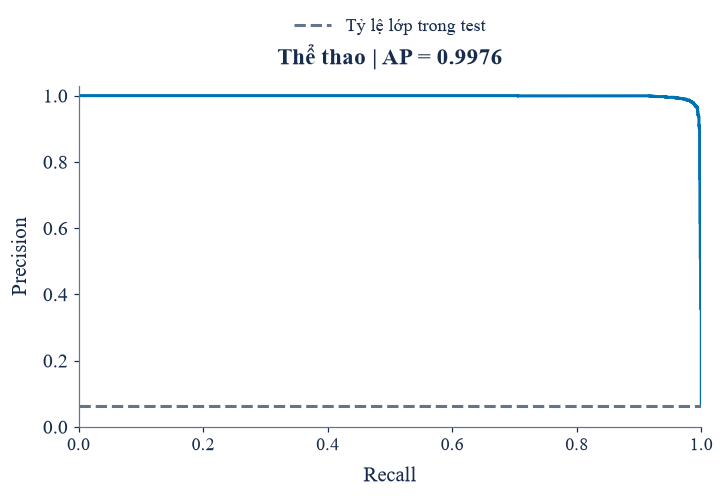

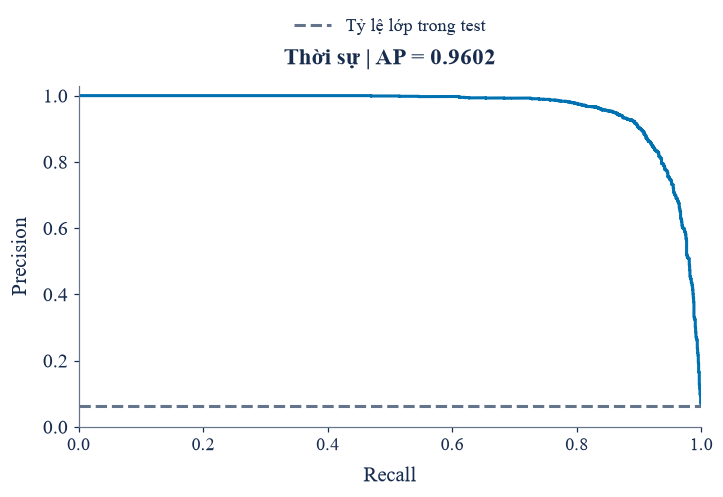

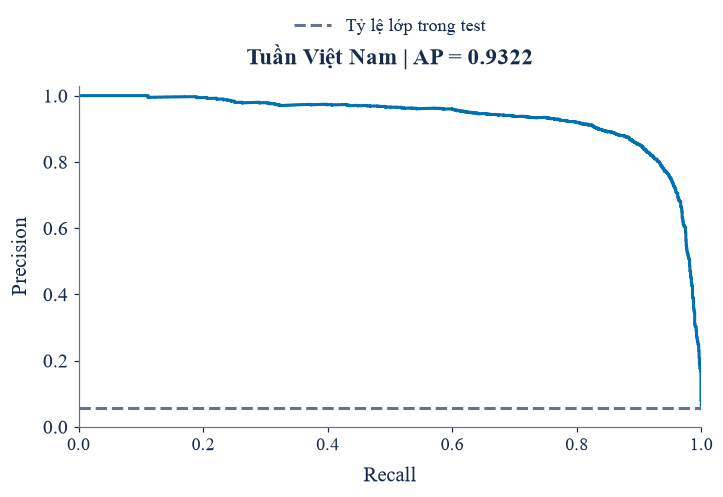

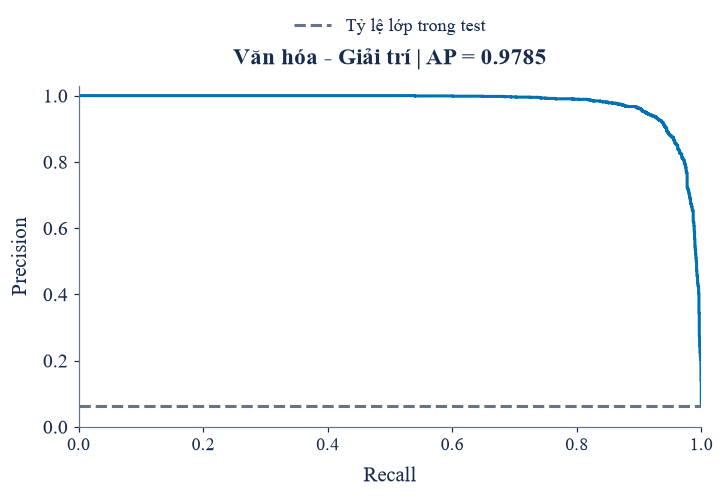

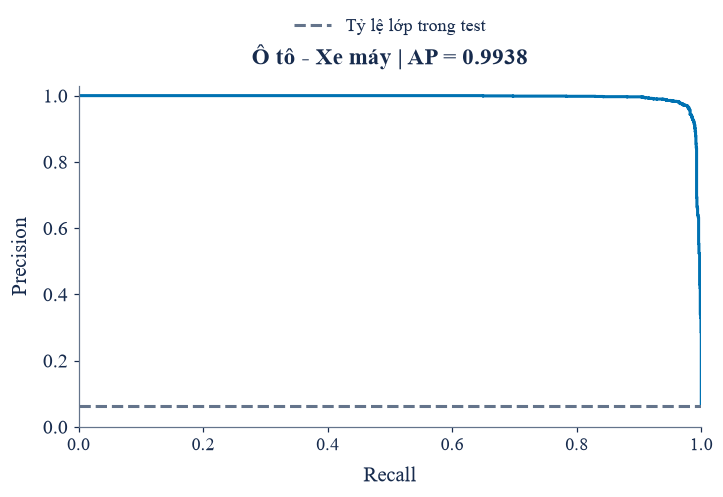

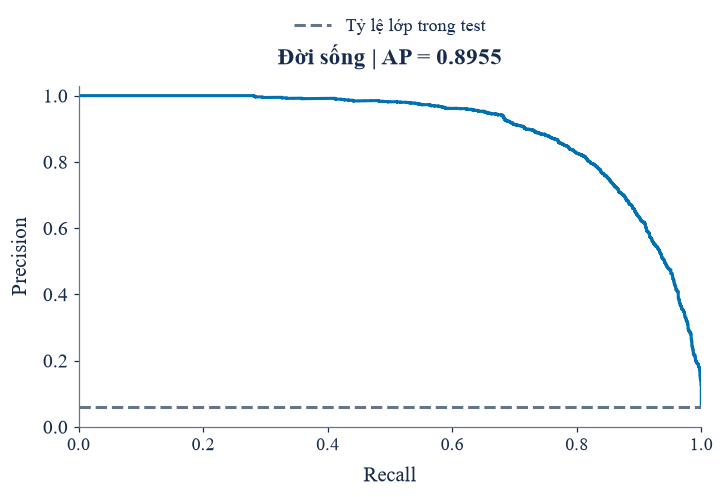

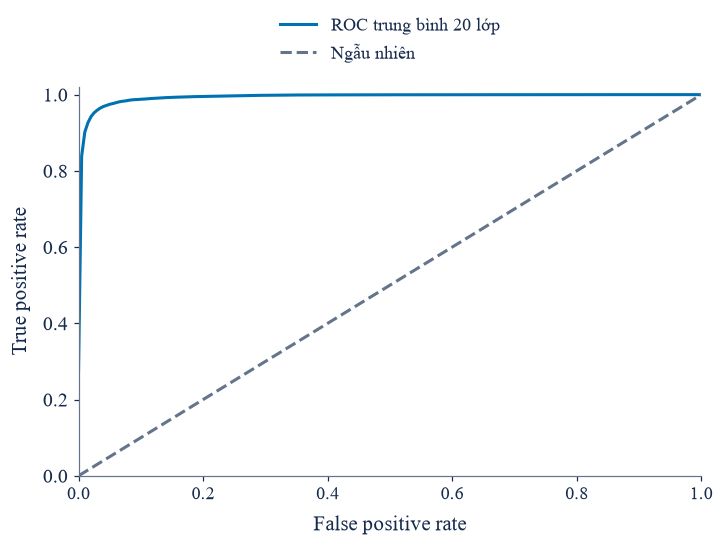

In [30]:
matrix_plot(matrix, 'evaluation/confusion_matrix')
matrix_plot(matrix, 'evaluation/confusion_matrix_normalized', normalized=True)
for metric, title in [('precision', 'Precision'), ('recall', 'Recall'), ('f1-score', 'F1')]:
    horizontal_plot(np.array([report[label][metric] for label in classes]), classes,
                    f'{title} theo chuyên mục', title,
                    'evaluation/per_class_' + metric.replace('-score', ''), limit=1.12)
pairs = sorted([(int(matrix[i, j]), i, j) for i in range(N_CLASSES)
                 for j in range(N_CLASSES) if i != j and matrix[i, j]], reverse=True)[:12]
if pairs:
    horizontal_plot(np.array([item[0] for item in pairs]),
                    [f'{item[1]} → {item[2]}' for item in pairs],
                    'Các cặp nhãn nhầm lẫn nhiều nhất', 'Số bài báo', 'evaluation/top_confusions')
fig, ax = plt.subplots(figsize=(8.2, 5.8))
support = np.array([report[label]['support'] for label in classes])
f1_values = np.array([report[label]['f1-score'] for label in classes])
ax.scatter(support, f1_values, color=COLORS['primary'], alpha=0.75, s=65)
for i in range(N_CLASSES):
    if support[i] < np.quantile(support, 0.25) or f1_values[i] < np.quantile(f1_values, 0.25):
        ax.annotate(str(i), (support[i], f1_values[i]), xytext=(5, 5),
                    textcoords='offset points', fontsize=10)
ax.set(xlabel='Số mẫu test của lớp', ylabel='F1', ylim=(0, 1.06),
       title='Quy mô lớp và chất lượng phân loại (chú thích bằng ID)')
ax.grid(alpha=0.18)
save_fig(fig, 'evaluation/support_vs_f1')
for name, diagnostic in [('before', before), ('temperature', after)]:
    fig, ax = plt.subplots(figsize=(6.8, 5.4))
    rows = diagnostic['bins']
    ax.plot([0, 1], [0, 1], '--', color=COLORS['muted'], label='Hiệu chỉnh lý tưởng')
    ax.plot([row['confidence'] for row in rows], [row['accuracy'] for row in rows],
            'o-', color=COLORS['primary'], label='Mô hình')
    ax.set(xlabel='Độ tin cậy trung bình', ylabel='Tỷ lệ dự đoán đúng',
           xlim=(0, 1), ylim=(0, 1), title=f'ECE (15 bins): {diagnostic["ece_15_bins"]:.4f}')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.10), ncol=2, frameon=False)
    ax.grid(alpha=0.18)
    save_fig(fig, 'evaluation/reliability_' + name)
for name, values in [('nll', [before['nll'], after['nll']]),
                      ('ece', [before['ece_15_bins'], after['ece_15_bins']])]:
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    ax.bar(['Chưa hiệu chỉnh', 'Temperature'], values,
            color=[COLORS['primary'], COLORS['secondary']])
    ax.set(ylabel='NLL' if name == 'nll' else 'ECE (15 bins)')
    save_fig(fig, 'evaluation/' + name + '_comparison')
fig, ax = plt.subplots(figsize=(7.8, 4.8))
confidence = test_probabilities.max(axis=1)
correct = y_test == test_predictions
for mask, title, color in [(correct, 'Đúng', 'primary'), (~correct, 'Sai', 'warning')]:
    ax.hist(confidence[mask], bins=np.linspace(0, 1, 26), alpha=0.7,
             label=title, color=COLORS[color])
ax.set(xlabel='Độ tin cậy sau temperature', ylabel='Số bài báo')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
save_fig(fig, 'evaluation/confidence')
curves = []
common_fpr = np.linspace(0, 1, 200)
for i, label in enumerate(classes):
    binary = (y_test == i).astype(int)
    precision, recall, _ = precision_recall_curve(binary, test_probabilities[:, i])
    ap = float(average_precision_score(binary, test_probabilities[:, i]))
    fpr, tpr, _ = roc_curve(binary, test_probabilities[:, i])
    curves.append({'id': i, 'label': label, 'average_precision': ap,
                   'roc_auc': float(auc(fpr, tpr)),
                   'interpolated_tpr': np.interp(common_fpr, fpr, tpr).tolist()})
    fig, ax = plt.subplots(figsize=(6.8, 4.8))
    ax.step(recall, precision, where='post', color=COLORS['primary'])
    ax.axhline(binary.mean(), ls='--', color=COLORS['muted'], label='Tỷ lệ lớp trong test')
    ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.03),
           title=f'{label} | AP = {ap:.4f}')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.10), frameon=False)
    save_fig(fig, f'evaluation/precision_recall/class_{i:02d}')
write_json(EVALUATION_DIR / 'ranking_metrics.json', [
    {key: value for key, value in row.items() if key != 'interpolated_tpr'} for row in curves])
fig, ax = plt.subplots(figsize=(6.8, 5.2))
ax.plot(common_fpr, np.mean([row['interpolated_tpr'] for row in curves], axis=0),
        color=COLORS['primary'], label='ROC trung bình 20 lớp')
ax.plot([0, 1], [0, 1], '--', color=COLORS['muted'], label='Ngẫu nhiên')
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), frameon=False)
save_fig(fig, 'evaluation/macro_roc')


In [31]:
image_paths = sorted(FIGURE_DIR.rglob('*.png'))
write_json(RESULT_DIR / 'figure_manifest.json', {
    'model': MODEL_KEY, 'format': 'PNG', 'dpi': 300,
    'files': [{'path': path.relative_to(RESULT_DIR).as_posix(),
               'sha256': file_sha256(path)} for path in image_paths],
})
write_json(MODEL_DIR / 'artifact_manifest.json', {
    'model': MODEL_KEY, 'corpus_signature': corpus_signature,
    'split_signature': split_signature,
    'files': [{'name': path.name, 'sha256': file_sha256(path)}
              for path in sorted(MODEL_DIR.iterdir())
              if path.is_file() and path.name != 'artifact_manifest.json'],
})
log(f'Hoàn tất: {len(image_paths)} PNG độc lập; model tại {MODEL_DIR}; kết quả tại {RESULT_DIR}.')
log('Bảng đối chiếu: comparison summary; chỉ chứa cấu hình được chọn bằng validation.')
display(pd.DataFrame([{
    'Mô hình': MODEL_NAME, 'Accuracy': test_metrics['accuracy'],
    'Macro-F1': test_metrics['f1_macro'], 'Weighted-F1': test_metrics['f1_weighted'],
    'NLL sau hiệu chỉnh': after['nll'], 'ECE sau hiệu chỉnh': after['ece_15_bins'],
    'Số mẫu test': len(y_test),
}]))


# Hoàn tất: 53 PNG độc lập; model tại C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\model\lstm; kết quả tại C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\result\lstm.
# Bảng đối chiếu: comparison summary; chỉ chứa cấu hình được chọn bằng validation.


,Mô hình,Accuracy,Macro-F1,Weighted-F1,NLL sau hiệu chỉnh,ECE sau hiệu chỉnh,Số mẫu test
0,BiLSTM,0.886648,0.845995,0.887105,0.368136,0.011488,29995


## Sử dụng kết quả trong báo cáo

`result/lstm/evaluation/comparison_summary.json` chứa duy nhất cấu hình được
chọn và kết quả test cùng fingerprint corpus, split, hash URL test. Báo cáo
cần ghi BiLSTM, embedding học từ đầu, vocabulary, chiều dài **từ**, số hướng,
hidden size, dropout, trọng số lớp, epoch tốt nhất và tổng chi phí tìm tham số.

Thời gian inference gồm DataLoader, chuyển GPU và forward, không gồm phân
đoạn/mã hóa. Từ ngoài vocabulary, mất thông tin do cắt Head–Tail và khác biệt
đơn vị từ/subword là các yếu tố cần phân tích. Khoảng tin cậy bootstrap không
thay thế thực nghiệm nhiều seed. Không diễn giải temperature như tăng F1.
`continue` cộng thêm tối đa 10 epoch, giữ checkpoint đầu vào nếu các epoch mới
không cải thiện; đồ thị nối toàn bộ lịch sử của cấu hình được chọn.

Tài liệu: [PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html),
[Packed sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html),
[Automatic Mixed Precision](https://docs.pytorch.org/docs/stable/notes/amp_examples.html).
